# 線性回歸（—）

- **核心原理**：最小平方法、梯度下降
- **變體**：Ridge（L2）、Lasso（L1）、Elastic Net；多項式特徵
- **推薦資料集**：California Housing（20,640 筆、8 個連續特徵；目標是街區房價中位數，單位十萬美元、上限 5）

本章依照 README 的「每章標準流程」：EDA → Baseline → 手寫模型 → 套件實作 → 調參 → 測試集評估 → 診斷 → 本章小結。

> 第 1 節的 EDA 小結（TODO 1）、第 2 節 Baseline（TODO 2）、第 5 節調參（TODO 12–16）與第 7 節的 TODO 17 (4) 是依新版流程**補寫**的，答案由 Claude 撰寫，標題註明「補寫」；其餘題目沿用原本的作答。


---
## 1. 資料與探索性資料分析（EDA）

觀察直接寫在每格程式最上面的註解（`# 觀察：`）。


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from ml_dl_llm.data import load_california_housing

X_train, X_test, y_train, y_test = load_california_housing()
train = X_train.assign(label=y_train)

print("train / test：", X_train.shape, X_test.shape)


train / test： (16512, 8) (4128, 8)


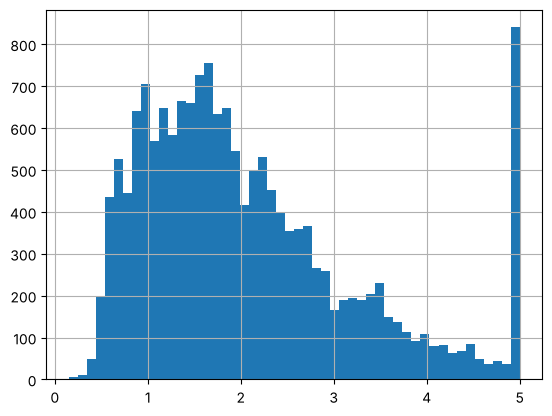

y 的最大值： 5.00001   等於最大值的筆數： 786 （4.8%）


In [2]:
# 觀察：目標值 y 的上限是 5（十萬美元）—— 不論真實房價是 50 萬、60 萬還是更高，都被記成 5.00001（右尾一根高柱）。
#   訓練集有 786 筆（4.8%）剛好是 5.00001：這是「截斷」（censoring），不是真的有一堆房子剛好 50 萬（TODO 1 (1)）。
y_train.hist(bins=50)
plt.show()
print("y 的最大值：", y_train.max(), "  等於最大值的筆數：", int((y_train == y_train.max()).sum()),
      f"（{(y_train == y_train.max()).mean():.1%}）")


In [3]:
# 觀察：變數全部都是連續型變數（float64），沒有缺值 → 不需要補值或類別編碼。
X_train.info()


<class 'pandas.DataFrame'>
Index: 16512 entries, 14196 to 15795
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      16512 non-null  float64
 1   HouseAge    16512 non-null  float64
 2   AveRooms    16512 non-null  float64
 3   AveBedrms   16512 non-null  float64
 4   Population  16512 non-null  float64
 5   AveOccup    16512 non-null  float64
 6   Latitude    16512 non-null  float64
 7   Longitude   16512 non-null  float64
dtypes: float64(8)
memory usage: 1.1 MB


In [4]:
# 觀察：變數的尺度差異極大（Population ~10³、AveBedrms ~1），梯度下降時下降方向會被尺度較大的變數主導，
#   導致收斂的步數變多或時間變長（3B 驗證）。
#   AveRooms 的最大值有 141.9 間、AveBedrms 有 25.6 間，不能說不合理，但這種極端值會把平均直接帶偏；
#   這些樣本可能是 outliers，也許該適度處理，但需要先判斷誰是 outlier（下一格、TODO 1 (2)）。
X_train.describe().T


,count,mean,std,min,25%,50%,75%,max
MedInc,16512.0,3.880754,1.904294,0.499900,2.566700,3.545800,4.773175,15.000100
HouseAge,16512.0,28.608285,12.602499,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,16512.0,5.435235,2.387375,0.888889,4.452055,5.235874,6.061037,141.909091
AveBedrms,16512.0,1.096685,0.433215,0.333333,1.006508,1.049286,1.100348,25.636364
Population,16512.0,1426.453004,1137.056380,3.000000,789.000000,1167.000000,1726.000000,35682.000000
AveOccup,16512.0,3.096961,11.578744,0.692308,2.428799,2.817240,3.280000,1243.333333
Latitude,16512.0,35.643149,2.136665,32.550000,33.930000,34.260000,37.720000,41.950000
Longitude,16512.0,-119.582290,2.005654,-124.350000,-121.810000,-118.510000,-118.010000,-114.310000


In [5]:
# 觀察：與 label 相關最高的是 MedInc（0.69），其餘都 < 0.16（AveRooms 0.158、Latitude −0.143）。
#   單變量相關係數只看「一次只看一個特徵」的線性關係；多元回歸的係數可能跟它方向相反（TODO 4 (3)）。
X_train.assign(label=y_train).corr().sort_values(by="label", ascending=False)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,label
label,0.690647,0.103706,0.158485,-0.051351,-0.026032,-0.022030,-0.142983,-0.046349,1.000000
MedInc,1.000000,-0.121711,0.336013,-0.072550,0.004122,0.022061,-0.076571,-0.017040,0.690647
AveRooms,0.336013,-0.160892,1.000000,0.836163,-0.073733,-0.004922,0.110695,-0.029339,0.158485
HouseAge,-0.121711,1.000000,-0.160892,-0.087983,-0.292283,0.016245,0.005296,-0.101818,0.103706
AveOccup,0.022061,0.016245,-0.004922,-0.006035,0.072330,1.000000,0.005837,-0.000598,-0.022030
Population,0.004122,-0.292283,-0.073733,-0.071267,1.000000,0.072330,-0.102499,0.094276,-0.026032
Longitude,-0.017040,-0.101818,-0.029339,0.016647,0.094276,-0.000598,-0.924485,1.000000,-0.046349
AveBedrms,-0.072550,-0.087983,0.836163,1.000000,-0.071267,-0.006035,0.073161,0.016647,-0.051351
Latitude,-0.076571,0.005296,0.110695,0.073161,-0.102499,0.005837,1.000000,-0.924485,-0.142983


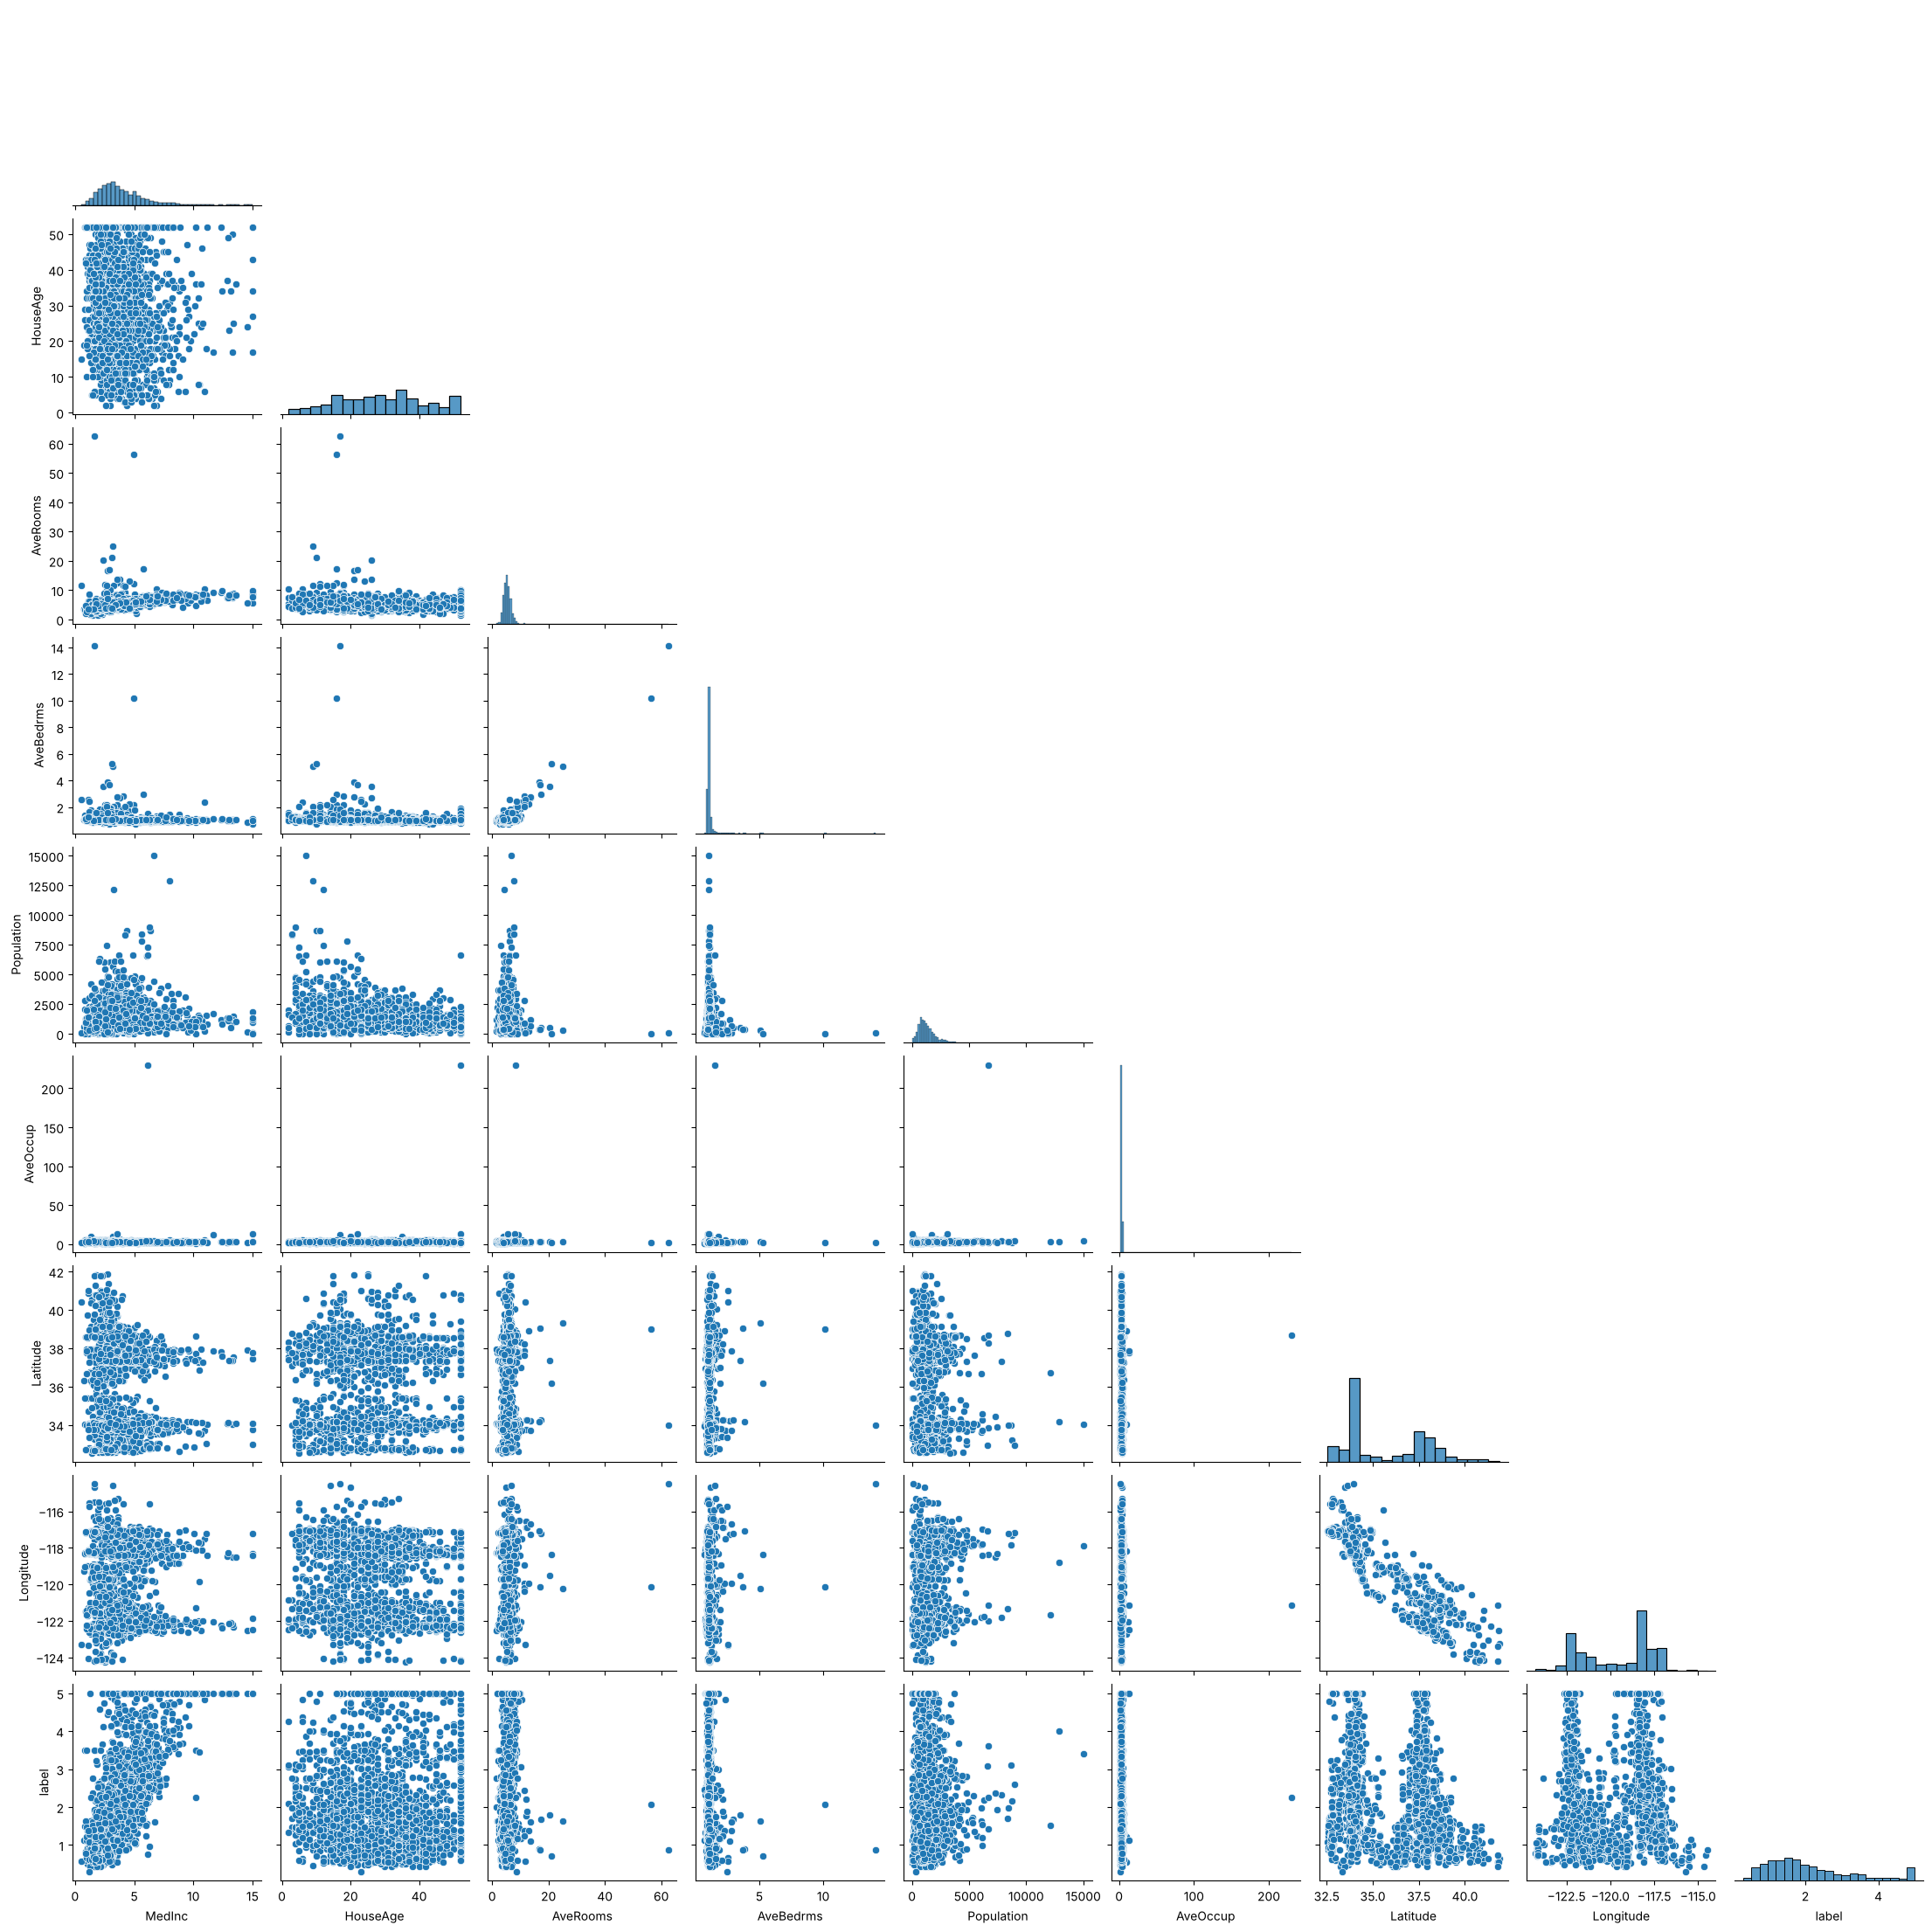

In [6]:
# 觀察：AveRooms、AveBedrms 的相關係數高達 0.836，已經是高度共線性了：
#   實務上可能導致梯度下降收斂變慢，對閉式解則會讓係數估計不穩定（TODO 4 (3)、TODO 10）。
#   Latitude、Longitude 的相關係數也很高（−0.92），是負相關。
sns.pairplot(X_train.assign(label=y_train).sample(2000, random_state=42), corner=True)
plt.show()


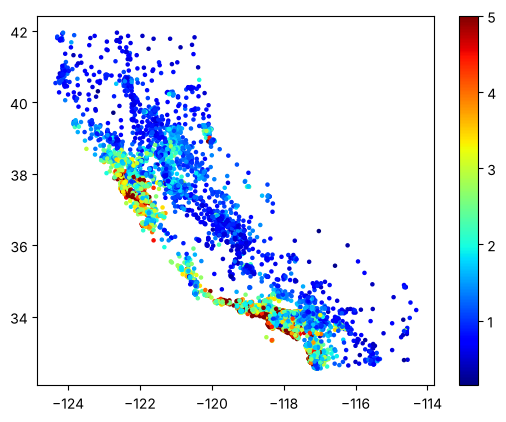

In [7]:
# 觀察：剛好是加州的形狀，可以看出靠海的房子房價越高（舊金山灣區、洛杉磯一帶）。
#   但對線性模型來說只有 w₁·lat + w₂·lon 一個平面：模型並不知道是否靠海，只能表達「緯度越低、經度越往西房價越高」
#   這種單一方向的趨勢（TODO 1 (3)、第 5 節用多項式特徵驗證）。
scatter = plt.scatter(train["Longitude"], train["Latitude"], c=train["label"], cmap="jet", s=5)
plt.colorbar(scatter)
plt.show()


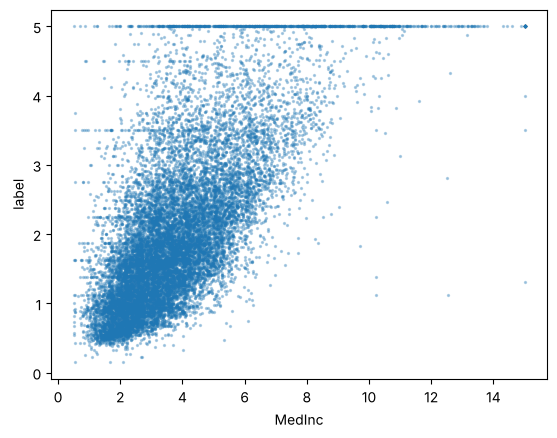

In [8]:
# 觀察：MedInc 與 label 大致正相關，但上方 y = 5 有一條水平線（截斷），4.5、3.5 附近也看得出可能有水平線
#   （原始資料在整數價位的堆積）。MedInc 高時 y 被 5 壓住 → 關係在右上角「彎平」，不是直線。
plt.scatter(train["MedInc"], train["label"], s=2, alpha=0.3)
plt.xlabel("MedInc")
plt.ylabel("label")
plt.show()


In [9]:
# 長尾與極端值（補寫）
# 觀察：AveRooms、AveBedrms、AveOccup 的偏態（skew）是 18.6、23.2、88.1，Population 也有 5.3（常態分布 = 0）。
#   極端值不是「稍微大一點」：AveOccup 的 99 百分位是 5.4 人／戶，最大值卻是 1,243（≈ 230 倍）；
#   AveRooms 最大值是 99 百分位的 14 倍。這幾個街區多半是度假屋、宿舍、監獄之類的特殊地點。
#   取 log1p 之後偏態大幅下降（AveOccup 88 → 4.3、AveRooms 18.6 → 1.3）→ 第 5 節把「要不要取 log」當成超參數。
SKEWED = ["AveRooms", "AveBedrms", "Population", "AveOccup"]
q = X_train.quantile([0.5, 0.99]).T
tail = q.assign(
    max=X_train.max(),
    max_over_p99=X_train.max() / q[0.99],
    skew=X_train.skew(),
    skew_after_log1p=np.log1p(X_train[SKEWED]).skew(),
)
display(tail.round(2))


,0.5,0.99,max,max_over_p99,skew,skew_after_log1p
MedInc,3.55,10.58,15.00,1.42,1.63,NaN
HouseAge,29.00,52.00,52.00,1.00,0.06,NaN
AveRooms,5.24,10.32,141.91,13.75,18.61,1.34
AveBedrms,1.05,2.12,25.64,12.11,23.17,8.66
Population,1167.00,5798.72,35682.00,6.15,5.28,-1.03
AveOccup,2.82,5.41,1243.33,229.81,88.05,4.26
Latitude,34.26,40.65,41.95,1.03,0.46,NaN
Longitude,-118.51,-116.31,-114.31,0.98,-0.29,NaN


### TODO 1（問答，補寫）EDA 小結

> **(1)** y 被截斷在 5：
>
> **(a)** 有幾筆、佔多少比例是 5.00001？
>
> **(b)** 線性模型最小化 MSE，會盡量讓「平均」預測對。這些樣本真實房價其實 ≥ 50 萬，標籤卻被壓低成 50 萬 —— 預期模型在高價區會高估還是低估？
>
> **(c)** 先寫下你的預測：這會在殘差圖（第 7 節）上留下什麼形狀？

**(a)** 786 筆（4.8%）恰為 5.00001。

**(b)** **低估**。高價街區的特徵（MedInc 高、靠海）指向「比 50 萬還貴」，但它們的標籤被壓成 5，模型為了把這些樣本的誤差平方降低，會把高價區的整體斜率往下拉 —— 不只截斷樣本本身，連附近其他高價樣本也會被拉低。

- 截斷（censoring）≠ 雜訊：雜訊是隨機的、平均為 0；截斷是**有方向的偏差**（真值一定 ≥ 標籤），MSE 無法自己修正。

**(c)** 殘差 = 實際 − 預測。實際固定為 5，所以殘差 $= 5 - \hat y$：對 $\hat y$ 作圖會是一條**斜率 −1 的直線**（TODO 17 (2) 驗證）。

> **(2)** 長尾與極端值（上一格）：
>
> **(a)** AveOccup 的最大值是 99 百分位的幾倍？取 log1p 後偏態從多少降到多少？
>
> **(b)** 線性模型的預測是 $\hat y = w \cdot x + b$，對 $x$ 沒有上限。一個 AveOccup = 1243 的樣本，就算 $w$ 很小，$w \cdot x$ 會怎樣？如果再加上 $x^2$、$x^3$ 這種多項式特徵呢？
>
> **(c)** 哪一種前處理能讓極端值「不那麼極端」，同時保留大小順序？

**(a)** 約 230 倍（5.4 → 1,243）。偏態 88.1 → 4.3；AveRooms 18.6 → 1.3、AveBedrms 23.2 → 8.7、Population 5.3 → −1.0。

**(b)** 線性項：$w \cdot 1243$ 是一般樣本（約 3）的 400 倍，一個小係數就能讓這筆的預測偏很多；而且 MSE 對誤差取平方，模型為了遷就這幾筆，會把係數往奇怪的方向扭（高槓桿點，leverage）。

多項式：$1243^2 \approx 1.5\times10^6$、$1243^3 \approx 1.9\times10^9$，比一般樣本大好幾個數量級。訓練時若某個 fold 沒看過這麼極端的值，係數在那個方向幾乎沒被約束 → 遇到它時預測可能飛到幾十、幾百（外插，extrapolation）。（第 5 節 TODO 13 驗證：二次多項式的某個 fold 有樣本被預測成 240，真值只有 1.4。）

**(c)** **取 log**（`np.log1p`，加 1 避免 log 0）：單調遞增 → 大小順序不變；但把「乘法尺度」壓成「加法尺度」，1,243 變成 7.1、5.4 變成 1.9。其他做法：截尾（clip 在某個百分位）、`QuantileTransformer`。

- 標準化（StandardScaler）**不能**解決：它只是平移＋縮放，形狀不變，極端值標準化後仍然極端（AveOccup 的 1243 會變成約 100 個標準差）。

> **(3)** 經緯度地圖：高價區集中在海岸邊的幾個聚落。線性模型 $w_1 \cdot \text{lat} + w_2 \cdot \text{lon}$ 能表達「靠海」嗎？預期線性回歸是過擬合還是欠擬合？

不能。$w_1 \cdot \text{lat} + w_2 \cdot \text{lon}$ 在地圖上是一個**傾斜的平面**：只能表達「往某個方向越走越貴」。海岸線是彎的、高價區是幾個分散的聚落（灣區、洛杉磯、聖地牙哥），要用平面同時貼合它們不可能。

- → 預期**欠擬合**（高偏差）：8 個特徵、16,512 筆資料，模型太簡單而不是太複雜；train 與 validation 的誤差會很接近、而且都偏高（第 5 節 TODO 12 驗證）。
- 改善方向：讓模型能表達曲面（多項式／交互作用項，第 5 節），或直接做「到海岸的距離」這類特徵（待補強）。


---
## 2. Baseline

最笨的回歸模型：**不看 $x$，永遠預測同一個數字**（`DummyRegressor`）。

- `strategy="mean"`：預測訓練集 y 的平均
- `strategy="median"`：預測訓練集 y 的中位數

指標（整章共用）：
- **RMSE**：主要指標，跟訓練目標 MSE 同一族、單位與 y 相同（十萬美元）
- **MAE**：平均絕對誤差，對少數大誤差較不敏感
- **R²**：$1 - \text{SSE}/\text{SST}$，「比永遠猜平均好多少」


In [10]:
from sklearn.base import BaseEstimator
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_validate

# 整章共用的 5-fold（打亂、固定 seed），所有 CV 分數才能互相比較
cv = KFold(n_splits=5, shuffle=True, random_state=42)
SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}


def cv_summary(
    model: BaseEstimator, X: pd.DataFrame = X_train, y: pd.Series = y_train
) -> dict[str, str]:
    """5-fold CV。回傳 {"rmse": "平均 ± 標準差", "mae": ..., "r2": ...}；rmse、mae 已轉回正值（越低越好）。"""
    s = cross_validate(model, X, y, cv=cv, scoring=SCORING)
    out = {}
    for k in SCORING:
        v = s[f"test_{k}"] * (1 if k == "r2" else -1)
        out[k] = f"{v.mean():.4f} ± {v.std():.4f}"
    return out


baseline = pd.DataFrame(
    {
        "Dummy mean": cv_summary(DummyRegressor(strategy="mean")),
        "Dummy median": cv_summary(DummyRegressor(strategy="median")),
    }
).T
display(baseline)
print("y_train：平均", round(float(y_train.mean()), 4), "  中位數", round(float(y_train.median()), 4),
      "  標準差（ddof=0）", round(float(y_train.std(ddof=0)), 4))


,rmse,mae,r2
Dummy mean,1.1562 ± 0.0122,0.9139 ± 0.0101,-0.0002 ± 0.0002
Dummy median,1.1878 ± 0.0128,0.8860 ± 0.0092,-0.0557 ± 0.0068


y_train：平均 2.0719   中位數 1.7985   標準差（ddof=0） 1.1562


### TODO 2（問答，補寫）

> **(1)** Dummy mean：
>
> **(a)** 它的 RMSE 跟 y_train 的哪一個統計量幾乎一樣？R² 是多少？
>
> **(b)** 定義：$R^2 = 1 - \dfrac{\sum (y_i - \hat y_i)^2}{\sum (y_i - \bar y)^2}$。把 $\hat y_i = \bar y$ 代進去會得到多少？
>
> **(c)** 那為什麼 CV 的 R² 是「略小於 0」（−0.0002），而不是剛好 0？

**(a)** RMSE 1.1562 ≈ y_train 的標準差 1.1562；R² ≈ 0。

**(b)** 分子與分母一模一樣 → $R^2 = 0$。

- 同理 $\text{RMSE} = \sqrt{\frac{1}{n}\sum(y_i - \bar y)^2}$ 正好是 y 的（母體）標準差 —— 「永遠猜平均」的誤差就是 y 本身的散布程度。
- 所以 R² 的意思是「比永遠猜平均，把平方誤差降低了幾成」；R² = 0.6 ⇔ MSE 只剩 baseline 的 40%。

**(c)** CV 時，Dummy 猜的是「訓練 fold」的平均，評分卻用「驗證 fold」：R² 的分母用的是驗證 fold 自己的平均 $\bar y_\text{val}$，而預測值是 $\bar y_\text{train} \ne \bar y_\text{val}$，所以分子一定 ≥ 分母，R² ≤ 0。

- 推論：**R² 可以是負的**（測試集上比「猜測試集平均」還差），不是 0–1 之間的比例。

> **(2)** Dummy median 的 MAE 比 mean 好（0.886 vs 0.914），RMSE 卻比較差（1.188 vs 1.156）。為什麼兩個指標的結論相反？（提示：哪一個常數讓 $\sum (y_i - c)^2$ 最小？哪一個讓 $\sum |y_i - c|$ 最小？）

- $\sum (y_i - c)^2$ 對 $c$ 微分 $= -2\sum(y_i - c) = 0$ → $c = \bar y$：**平均**是平方誤差最小的常數。
- $\sum |y_i - c|$ 對 $c$ 的（次）梯度 $= (\#\{y_i < c\}) - (\#\{y_i > c\})$，等於 0 時 $c$ 左右各一半 → **中位數**是絕對誤差最小的常數。
- 兩個 Dummy 各自在「自己的指標」上最佳，所以結論相反。y 右偏（平均 2.07 > 中位數 1.80，又有截斷在 5 的長尾），兩者差得夠多，指標差異才看得出來。

**推論**：

- 選指標 = 選「要最小化哪一種誤差」：MSE／RMSE 對大誤差特別敏感（平方），MAE 對每一筆一視同仁。
- 線性回歸最小化 MSE，所以它的預測是條件**平均** $E[y \mid x]$；想要條件中位數要換 loss（quantile regression，待補強）。
- 這個差異在第 5 節會再出現：多項式模型的 MAE 變好、RMSE 卻爆掉（TODO 13）。


---
## 3. 手寫模型

### 3A. 正規方程（Normal Equation）

最小化 ‖Xw − y‖²，對 w 微分令其為 0 → **w = (XᵀX)⁻¹ Xᵀ y**

建議先在紙上推一次再寫。

In [11]:
from typing import Self

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.typing import ArrayLike
from sklearn.preprocessing import StandardScaler
from ml_dl_llm.data import load_california_housing
from ml_dl_llm.metrics import regression_metrics

X_train, X_test, y_train, y_test = load_california_housing()
feature_names = X_train.columns.tolist()

# 只用訓練集 fit scaler，再套到測試集（避免資料洩漏）
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)


def add_bias(X: ArrayLike) -> np.ndarray:
    """在 X 最左邊補一欄 1，讓 bias 變成係數向量的第 0 個元素。X (n, d) → (n, d + 1)。"""
    X = np.asarray(X, dtype=float)
    return np.c_[np.ones(len(X)), X]


class LinearRegressionNE:
    """用正規方程一步求解。"""

    def fit(self, X: ArrayLike, y: ArrayLike) -> Self:
        """X (n, d)、y (n,)。學到 w_ (d,) 與 b_，回傳 self。"""
        Xb = add_bias(X)
        y = np.asarray(y, dtype=float)
        # TODO 3（程式）：解 (Xbᵀ Xb) θ = Xbᵀ y 得到 θ（長度 = 特徵數 + 1）
        #   - 用 np.linalg.solve(A, b)，不要用 np.linalg.inv（想想為什麼）
        #   - θ[0] 是 bias，θ[1:] 是各特徵權重
        theta = np.linalg.solve(Xb.T @ Xb, Xb.T @ y)
        self.b_ = theta[0]
        self.w_ = theta[1:]
        return self

    def predict(self, X: ArrayLike) -> np.ndarray:
        """X (n, d) → (n,) 的預測值。"""
        return np.asarray(X, dtype=float) @ self.w_ + self.b_

In [12]:
# 實驗：raw vs 標準化
ne_raw = LinearRegressionNE().fit(X_train, y_train)
ne_s = LinearRegressionNE().fit(X_train_s, y_train)

print("raw    train:", regression_metrics(y_train, ne_raw.predict(X_train)))
print("scaled train:", regression_metrics(y_train, ne_s.predict(X_train_s)))
print("兩者預測值最大差異：", np.abs(ne_raw.predict(X_train) - ne_s.predict(X_train_s)).max(),
      "（數學上相同；應 < 1e-6，差異來自 raw 的條件數）")
theta_ref = np.linalg.lstsq(add_bias(X_train_s), y_train.to_numpy(), rcond=None)[0]  # SVD 解，當標準答案
print("✅ 正規方程 vs np.linalg.lstsq 的最大差異（scaled）：",
      np.abs(np.r_[ne_s.b_, ne_s.w_] - theta_ref).max(), "（應 < 1e-10）")

coef = pd.DataFrame({"raw": ne_raw.w_, "scaled": ne_s.w_}, index=feature_names)
coef.loc["(bias)"] = [ne_raw.b_, ne_s.b_]
display(coef.round(4))

Xb_raw, Xb_s = add_bias(X_train), add_bias(X_train_s)
print(f"XᵀX 條件數 raw   ：{np.linalg.cond(Xb_raw.T @ Xb_raw):.3e}")
print(f"XᵀX 條件數 scaled：{np.linalg.cond(Xb_s.T @ Xb_s):.3e}")

raw    train: {'mae': 0.5286, 'rmse': 0.7197, 'r2': 0.6126, 'mape': 31.502}
scaled train: {'mae': 0.5286, 'rmse': 0.7197, 'r2': 0.6126, 'mape': 31.502}
兩者預測值最大差異： 4.6266990239018924e-11 （數學上相同；應 < 1e-6，差異來自 raw 的條件數）
✅ 正規方程 vs np.linalg.lstsq 的最大差異（scaled）： 1.1324274851176597e-14 （應 < 1e-10）


,raw,scaled
MedInc,0.4487,0.8544
HouseAge,0.0097,0.1225
AveRooms,-0.1233,-0.2944
AveBedrms,0.7831,0.3393
Population,-0.0000,-0.0023
AveOccup,-0.0035,-0.0408
Latitude,-0.4198,-0.8969
Longitude,-0.4337,-0.8698
(bias),-37.0233,2.0719


XᵀX 條件數 raw   ：5.642e+10
XᵀX 條件數 scaled：4.283e+01


### TODO 4（問答）

> **(1)** 預測值一樣嗎？係數一樣嗎？為什麼？

預測值幾乎一樣，這個寫法基本上只是矩陣的運算而已，理論上數值會一模一樣，現在看到有差異是因為電腦浮點數或是 solver 的精度導致的，並不是數學上本身有問題。

標準化只是對每一欄做 $x' = (x - \mu) / \sigma$，也就是縮放加平移。線性模型本身就有 $w$ 和 $b$ 可以調，縮放可以被 $w$ 吸收，平移可以被 $b$ 吸收。所以兩種資料能表達的函數完全一樣，最佳解的預測值也就一樣。

係數不一樣，係數之間有精確的換算關係：$w_\text{scaled} = w_\text{raw} \times \sigma$

> **(2)** 條件數差幾個數量級？

raw $\approx 5.6\times10^{10}$、scaled $\approx 4.3\times10^{1}$，差約 9 個數量級。

- 條件數 $\kappa = \lambda_\max / \lambda_\min$，代表誤差會被放大的倍數（$\kappa \approx 10^k$ 約損失 $k$ 位有效數字）。
- raw 的大 $\kappa$ 主要來自特徵尺度差異（Population ~$10^3$ vs AveBedrms ~1），標準化就能修掉；
  上面預測值差了 $10^{-9}$，正是 raw 的大 $\kappa$ 把浮點誤差（~$10^{-16}$）放大的結果。
- 另外 $\kappa(X^\top X) = \kappa(X)^2$，正規方程先算 $X^\top X$ 會把病態程度平方，所以 sklearn 改用 lstsq（SVD）。

> **(3)** AveRooms、AveBedrms 的係數正負號，跟它們和 y 的相關係數（0.158、-0.051）方向一致嗎？用共線性解釋。

兩個都相反：

| 特徵 | 與 y 的相關係數 | 多元回歸係數 |
| --- | --- | --- |
| AveRooms | +0.158 | −0.29 |
| AveBedrms | −0.051 | +0.34 |

- 相關係數只看單一特徵與 y 的關係；多元回歸係數是「其他特徵固定時」該特徵的效果，兩者回答不同問題。
- 兩者相關 0.84，幾乎同進同退，模型難以分辨功勞歸誰，常出現一正一負互相抵消的解，係數也因此不穩定。
  （白話：房間總數固定時，臥室比例越高、客廳等公共空間越少 → 這組係數不宜直接解讀為因果）
- 這是共線性的典型症狀，Ridge（加 $\alpha I$ 墊高 $\lambda_\min$）可以讓這組係數變穩定。

### 3B. 梯度下降（Gradient Descent）

Loss 用 MSE = (1/n) Σ (ŷᵢ − yᵢ)²，每個 epoch 用全部資料算一次梯度（full-batch）。
目標：收斂到跟正規方程**同一組**係數。

In [13]:
class LinearRegressionGD:
    """Full-batch 梯度下降，最小化 MSE。"""

    def __init__(self, lr: float = 0.1, n_epochs: int = 1000, tol: float = 1e-10) -> None:
        self.lr = lr
        self.n_epochs = n_epochs
        self.tol = tol  # loss 改善小於 tol 就提早停

    def fit(self, X: ArrayLike, y: ArrayLike) -> Self:
        """X (n, d)、y (n,)。學到 w_ (d,)、b_ 與每個 epoch 的 loss_history_，回傳 self。"""
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        n, d = X.shape
        self.w_ = np.zeros(d)
        self.b_ = 0.0
        self.loss_history_ = []

        for epoch in range(self.n_epochs):
            # TODO 5（程式）：前向計算
            #   y_hat：目前參數下的預測值，shape (n,)
            #   loss ：MSE（純量）
            y_hat = X @ self.w_ + self.b_
            residual = y_hat - y
            loss = (residual ** 2).mean()

            # TODO 6（程式）：梯度 —— MSE 分別對 w、b 偏微分
            #   grad_w shape (d,)、grad_b 是純量
            #   提示：先算殘差 r = y_hat - y，再用矩陣運算，不要寫 for 迴圈
            grad_w = (2 / n) * X.T @ residual
            grad_b = (2 / n) * np.sum(residual)

            # TODO 7（程式）：參數更新（兩行）
            self.w_ -= self.lr * grad_w
            self.b_ -= self.lr * grad_b

            self.loss_history_.append(loss)
            if not np.isfinite(loss):  # 發散就停
                break
            if epoch > 0 and abs(self.loss_history_[-2] - loss) < self.tol:
                break
        return self

    def predict(self, X: ArrayLike) -> np.ndarray:
        """X (n, d) → (n,) 的預測值。"""
        return np.asarray(X, dtype=float) @ self.w_ + self.b_

epochs： 776   final MSE： 0.5179331307166155
✅ w 與正規方程的最大差異： 0.00018890462820675413 （應 < 1e-3：loss 改善 < tol 就停，不是精確解）
✅ b 與正規方程的差異    ： 4.440892098500626e-16 （應 < 1e-10：標準化後 b 就是 y 的平均）


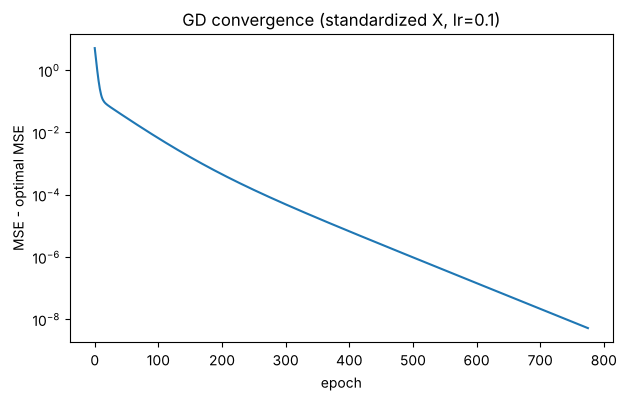

In [14]:
# 在標準化資料上跑，跟正規方程的解比對
gd = LinearRegressionGD(lr=0.1, n_epochs=5000).fit(X_train_s, y_train)
print("epochs：", len(gd.loss_history_), "  final MSE：", gd.loss_history_[-1])
print("✅ w 與正規方程的最大差異：", np.abs(gd.w_ - ne_s.w_).max(),
      "（應 < 1e-3：loss 改善 < tol 就停，不是精確解）")
print("✅ b 與正規方程的差異    ：", abs(gd.b_ - ne_s.b_), "（應 < 1e-10：標準化後 b 就是 y 的平均）")

best_mse = np.mean((ne_s.predict(X_train_s) - y_train) ** 2)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.maximum(np.array(gd.loss_history_) - best_mse, 1e-16))
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("MSE - optimal MSE")
ax.set_title("GD convergence (standardized X, lr=0.1)")
plt.show()

In [15]:
# 實驗：學習率 × 是否標準化
rows = []
with np.errstate(over="ignore", invalid="ignore"):
    for data_name, X in [("scaled", X_train_s), ("raw", X_train)]:
        for lr in [0.5, 0.1, 0.01, 1e-6, 1e-7]:
            m = LinearRegressionGD(lr=lr, n_epochs=2000).fit(X, y_train)
            rows.append({
                "data": data_name,
                "lr": lr,
                "epochs": len(m.loss_history_),
                "final_mse": m.loss_history_[-1],
            })
display(pd.DataFrame(rows))

,data,lr,epochs,final_mse
0,scaled,5.000000e-01,2000,2.289048e+40
1,scaled,1.000000e-01,776,5.179331e-01
2,scaled,1.000000e-02,2000,5.183998e-01
3,scaled,1.000000e-06,2000,5.589813e+00
4,scaled,1.000000e-07,2000,5.625735e+00
5,raw,5.000000e-01,25,inf
6,raw,1.000000e-01,28,inf
7,raw,1.000000e-02,33,inf
8,raw,1.000000e-06,203,inf
9,raw,1.000000e-07,2000,1.333204e+00


### TODO 8（問答）

記號：MSE 的 Hessian $H = \frac{2}{n} X_b^\top X_b$（含 bias 欄），$\lambda_\max$、$\lambda_\min$ 為其最大、最小特徵值，$\kappa = \lambda_\max / \lambda_\min$。實測：

| | $\lambda_\max$ | $\lambda_\min$ | $\kappa$ |
| --- | --- | --- | --- |
| raw | $\approx 6.7\times10^{6}$ | $\approx 1.2\times10^{-4}$ | $\approx 5.6\times10^{10}$ |
| scaled | $\approx 4.05$ | $\approx 0.095$ | $\approx 43$ |

> **(1)** raw 資料在哪些 lr 會發散？最大能用的 lr 大概多少？scaled 為什麼 lr=0.5 也會炸？

梯度下降在二次 loss 上，沿第 $i$ 個特徵方向的誤差每步乘上 $(1 - \text{lr}\cdot\lambda_i)$；只要有任一方向 $|1 - \text{lr}\cdot\lambda_i| > 1$ 就會逐步放大而發散，因此穩定條件為

$$\text{lr} < \frac{2}{\lambda_\max}$$

- raw：$2/\lambda_\max \approx 3.0\times10^{-7}$ → lr = 0.5、0.1、0.01、1e-6 皆超過上限而發散，只有 1e-7 穩定。
- scaled：$2/\lambda_\max \approx 0.494$ → lr = 0.5 略超過上限，同樣發散；0.1、0.01 都在範圍內。
- raw 的 $\lambda_\max$ 之所以極大，是因為 Population（數值 ~$10^3$）這類大尺度特徵讓 $X^\top X$ 在該方向的曲率非常陡。

> **(2)** raw 用不會發散的 lr 跑 2000 epochs，MSE 跟最佳解（約 0.52）差多少？為什麼這麼慢？

- raw、lr = 1e-7、2000 epochs 後 MSE ≈ 1.33，最佳解 ≈ 0.518，仍差約 0.8，遠未收斂。
- lr 被最陡方向限制在 ~$10^{-7}$，但在最平緩方向每步收縮因子 $1 - \text{lr}\cdot\lambda_\min \approx 1 - 10^{-11}$，幾乎不動。
- 收斂所需步數約 $O(\kappa) \approx 10^{10}$，2000 步相對而言等於沒有前進。
- 對照 scaled、lr = 0.1：最慢方向收縮因子 $\approx 1 - 0.1 \times 0.095 \approx 0.99$，約 776 步即收斂到 tol。

> **(3)** 連結到 TODO 4 的條件數：條件數大，對梯度下降代表什麼？

$\kappa$ 決定梯度下降的「收斂速度」：lr 上限由 $\lambda_\max$ 決定（$\text{lr} < 2/\lambda_\max$），最慢方向的進度由 $\text{lr}\cdot\lambda_\min$ 決定，兩者合起來使最慢方向每步收縮因子約為 $1 - 2/\kappa$，所需迭代次數約與 $\kappa$ 成正比。

- 幾何上，$\kappa$ 大代表 loss 等高線是細長的橢圓（狹長山谷）：梯度主要指向陡峭的谷壁而非谷底方向，於是在谷壁間來回震盪、沿谷底推進極慢。
- 注意：發散的直接原因是 $\text{lr} > 2/\lambda_\max$，而不是 $\kappa$ 本身；$\kappa$ 大的後果是「所有不發散的 lr 都慢到不可用」。
- 標準化把 $\kappa$ 從 $5.6\times10^{10}$ 降到 43，所以 scaled 版本能用大 lr 並在數百步內收斂。

（TODO 4 的「誤差放大」是 $\kappa$ 在直接解線性方程組時的意義；在梯度下降中 $\kappa$ 主要反映收斂速度。）

### 3C. Ridge（L2 正則化）

目標函數：‖y − Xw − b‖² + α‖w‖²（bias **不**懲罰，跟 sklearn 的定義相同）

閉式解：θ = (XbᵀXb + αI′)⁻¹ Xbᵀy，其中 I′ 是單位矩陣但 bias 那格為 0。

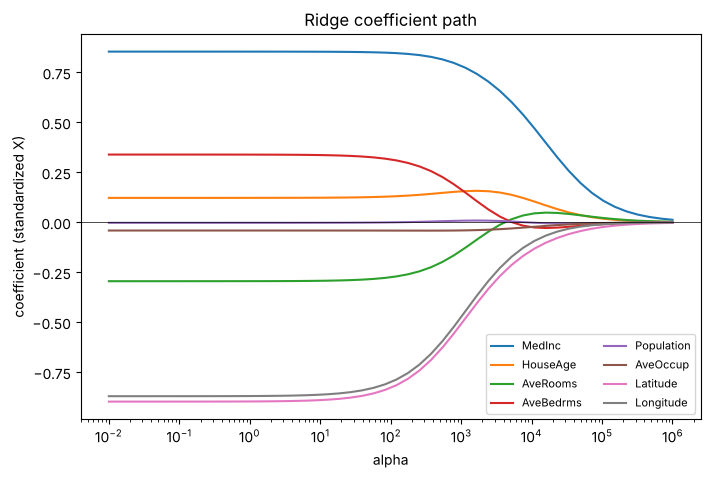

In [16]:
class RidgeNE(LinearRegressionNE):
    """Ridge 閉式解：最小化 ‖y − Xw − b‖² + α‖w‖²（bias 不懲罰）。"""

    def __init__(self, alpha: float = 1.0) -> None:
        self.alpha = alpha

    def fit(self, X: ArrayLike, y: ArrayLike) -> Self:
        """X (n, d)、y (n,)。學到 w_ (d,) 與 b_，回傳 self。"""
        Xb = add_bias(X)
        y = np.asarray(y, dtype=float)
        # TODO 9（程式）：Ridge 閉式解
        #   - 建一個 (d+1)×(d+1) 的單位矩陣，把 [0, 0] 設成 0（bias 不懲罰）
        #   - 一樣用 np.linalg.solve
        identity_matrix = np.identity(n=Xb.shape[1])
        identity_matrix[0, 0] = 0
        theta = np.linalg.solve(Xb.T @ Xb + self.alpha * identity_matrix, Xb.T @ y)
        self.b_, self.w_ = theta[0], theta[1:]
        return self


# 係數路徑：alpha 由小到大，看每個係數怎麼被壓向 0
alphas = np.logspace(-2, 6, 50)
paths = np.array([RidgeNE(a).fit(X_train_s, y_train).w_ for a in alphas])

fig, ax = plt.subplots(figsize=(8, 5))
for j, name in enumerate(feature_names):
    ax.plot(alphas, paths[:, j], label=name)
ax.set_xscale("log")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("alpha")
ax.set_ylabel("coefficient (standardized X)")
ax.set_title("Ridge coefficient path")
ax.legend(fontsize=8, ncol=2)
plt.show()

### TODO 10（問答）

> **(1)** AveRooms／AveBedrms、Latitude／Longitude 這兩組共線的係數，隨 alpha 變大怎麼變化？

- **整體**：$\alpha \to \infty$ 時所有係數單調或近單調地收縮至 0；$\alpha \lesssim 10^2$ 時係數幾乎等於 OLS 解（懲罰相對 $X^\top X$ 可忽略）。
- **AveRooms／AveBedrms**：OLS 下為一負一正（−0.29、+0.34）互相抵消；$\alpha$ 增大後 AveBedrms 降向 0，AveRooms 在 $\alpha \approx 3\times10^3$ 附近由負轉正，之後以小正值趨近 0 —— 符號回到與其相關係數（+0.158）相同的方向。
  - 原因：Ridge 解 $w = (X^\top X + \alpha I)^{-1} X^\top y$，當 $\alpha$ 遠大於 $X^\top X$ 的特徵值時 $w \approx X^\top y / \alpha$；在標準化資料上 $X^\top y$ ∝ 各特徵與 y 的相關係數，因此強正則化下係數的「方向」趨近單變量相關，不再區分共線特徵間的條件效果，OLS 中「一正一負互相抵消」的解被拆除。
- **Latitude／Longitude**：兩者與 y 的相關皆為負，故不翻號；兩條路徑幾乎重合、同步收縮 —— Ridge 對高度相關的特徵傾向把權重「平均分攤」，而非給出一大一小或一正一負的極端組合。
- （補充）HouseAge 在 $\alpha \approx 10^3$ 附近先微幅上升再下降：其他特徵被壓縮後，它暫時承接了部分解釋力，顯示 Ridge 路徑不一定對每個係數都單調。

> **(2)** 為什麼 Ridge 一定要在標準化後的資料上做？（想想 $\alpha\|w\|^2$ 對不同尺度的特徵公平嗎）

懲罰項 $\alpha\|w\|^2 = \alpha \sum_j w_j^2$ 對每個係數施加相同的懲罰，但係數大小取決於特徵的單位：若特徵 $x_j$ 放大 $c$ 倍，等價模型的係數縮小為 $w_j / c$，懲罰則變為原本的 $1/c^2$。

- 因此在 raw 資料上，數值大的特徵（如 Population ~$10^3$）係數本來就極小，幾乎不受懲罰；數值小的特徵係數較大，被不成比例地重罰。收縮程度取決於任意的單位選擇（美元 vs 萬美元），而非特徵的重要性。
- Ridge 解不具尺度不變性（scale equivariance），OLS 則有；標準化使各特徵 std = 1，懲罰才在特徵間公平。
- （注意：這與收斂無關 —— Ridge 有閉式解，且 $+\alpha I$ 會提高 $\lambda_\min$、降低條件數，數值上反而更穩定。）
- 實務：標準化也要只在訓練集 fit，用 `Pipeline(StandardScaler(), Ridge())` 可避免資料洩漏。

---
## 4. 套件實作：sklearn `LinearRegression`、`Ridge`、`Lasso`、`ElasticNet`

前處理一律包進 `Pipeline`：`fit` 時 scaler 只看訓練資料，`predict` 時自動套用同一組 μ、σ。


In [17]:
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.pipeline import make_pipeline

sk_models = {
    "LinearRegression (sklearn)": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge a=1 (sklearn)": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso a=0.01 (sklearn)": make_pipeline(StandardScaler(), Lasso(alpha=0.01)),
    "Lasso a=0.1 (sklearn)": make_pipeline(StandardScaler(), Lasso(alpha=0.1)),
    "ElasticNet a=0.01 (sklearn)": make_pipeline(StandardScaler(), ElasticNet(alpha=0.01, l1_ratio=0.5)),
}
for m in sk_models.values():
    m.fit(X_train, y_train)  # pipeline 吃原始資料

ridge_s = RidgeNE(1.0).fit(X_train_s, y_train)
coef = pd.DataFrame({name: m[-1].coef_ for name, m in sk_models.items()}, index=feature_names)
coef["scratch NE"] = ne_s.w_
coef["scratch Ridge a=1"] = ridge_s.w_
display(coef.round(4))

# 驗證：手寫和 sklearn 應該幾乎一模一樣（差異 ~1e-10 等級）
print("✅ NE    vs sklearn：", np.abs(sk_models["LinearRegression (sklearn)"][-1].coef_ - ne_s.w_).max(), "（應 < 1e-10）")
print("✅ Ridge vs sklearn：", np.abs(sk_models["Ridge a=1 (sklearn)"][-1].coef_ - ridge_s.w_).max(), "（應 < 1e-10）")

,LinearRegression (sklearn),Ridge a=1 (sklearn),Lasso a=0.01 (sklearn),Lasso a=0.1 (sklearn),ElasticNet a=0.01 (sklearn),scratch NE,scratch Ridge a=1
MedInc,0.8544,0.8543,0.8010,0.7106,0.8240,0.8544,0.8543
HouseAge,0.1225,0.1226,0.1271,0.1065,0.1300,0.1225,0.1226
AveRooms,-0.2944,-0.2942,-0.1628,-0.0000,-0.2161,-0.2944,-0.2942
AveBedrms,0.3393,0.3390,0.2062,0.0000,0.2563,0.3393,0.3390
Population,-0.0023,-0.0023,-0.0000,-0.0000,-0.0000,-0.0023,-0.0023
AveOccup,-0.0408,-0.0408,-0.0306,-0.0000,-0.0359,-0.0408,-0.0408
Latitude,-0.8969,-0.8962,-0.7901,-0.0115,-0.7884,-0.8969,-0.8962
Longitude,-0.8698,-0.8691,-0.7557,-0.0000,-0.7570,-0.8698,-0.8691


✅ NE    vs sklearn： 2.7755575615628914e-15 （應 < 1e-10）
✅ Ridge vs sklearn： 3.3306690738754696e-15 （應 < 1e-10）


### TODO 11（問答）

> **(1)** 把 Lasso 的 alpha 改成 0.1 再跑一次，哪些係數被壓成剛好 0？Ridge 會這樣嗎？

- Lasso $\alpha = 0.1$：AveRooms、AveBedrms、Population、AveOccup、Longitude 恰為 0，僅保留 MedInc、HouseAge、Latitude（≈ −0.01）。
- Lasso $\alpha = 0.01$：只有 Population 為 0，其餘係數較 OLS 小幅收縮。
- Ridge 不會產生恰為 0 的係數，只會連續收縮、在 $\alpha \to \infty$ 時漸近 0。

原因：

- L1 懲罰 $\alpha|w_j|$ 在 $w_j = 0$ 不可微，最佳條件為 $|x_j^\top(y - Xw)| \le n\alpha$ 時 $w_j = 0$（soft-thresholding），只要某特徵對殘差的解釋力不足以抵過懲罰，係數就被精確設為 0 → 稀疏解、兼具特徵選擇。
- L2 懲罰可微，梯度 $2\alpha w_j$ 在 $w_j \to 0$ 時跟著趨近 0，懲罰的「推力」消失，因此只縮小不歸零。
- 幾何上：L1 約束區域是菱形（尖角落在座標軸上），MSE 等高線易在尖角相切；L2 是圓，無尖角。

共線特徵的處理差異：Lasso 對 Latitude／Longitude 只保留一個、另一個歸零，且選誰不穩定；Ridge 則讓兩者係數相近並同步收縮（平均分攤）；ElasticNet（L1 + L2）介於兩者之間，能稀疏化又傾向成組保留相關特徵。

另注意：$\alpha = 0.1$ 幾乎砍掉經緯度，但 EDA 顯示地理位置對房價很重要 → 預期測試集表現明顯變差（過度正則化／欠擬合）。

> **(2)** Lasso a=0.01 和 Ridge a=1 的懲罰力道可以直接比嗎？

不能直接比較，原因有二：

① **目標函數的尺度不同**：

| 模型 | 目標函數 |
| --- | --- |
| Ridge（sklearn） | $\lVert y - Xw \rVert^2 + \alpha \lVert w \rVert_2^2$ |
| Lasso（sklearn） | $\frac{1}{2n} \lVert y - Xw \rVert^2 + \alpha \lVert w \rVert_1$ |

Lasso 的資料項除以 $2n$，等價於未正規化形式 $\|y - Xw\|^2 + 2n\alpha\|w\|_1$；本例 $n = 16512$，$\alpha = 0.01$ 對應 $2n\alpha \approx 330$，與 Ridge 的 $\alpha = 1$ 不在同一量級，這也是 Lasso $\alpha = 0.01$ 的收縮明顯大於 Ridge $\alpha = 1$ 的原因。

② **懲罰的函數形式不同**：$\|w\|_1$ 與 $\|w\|_2^2$ 對係數大小的反應不同（線性 vs 平方），即使尺度對齊也無法一對一換算。

- $\frac{1}{2n}$ 的作用：$\frac{1}{n}$ 使 $\alpha$ 的意義不隨樣本數改變（資料量加倍時同一 $\alpha$ 效果不變）；$\frac{1}{2}$ 用來抵消平方項微分產生的 2。
- （sklearn 的 Ridge 未除以 $n$ 屬於歷史慣例上的不一致，並非刻意設計。）
- 實務上 $\alpha$ 不靠手動比較，而是用交叉驗證選擇（`RidgeCV`、`LassoCV`）。

---
## 5. 調參（補寫）

全程只用 `X_train`（測試集鎖住），依 README「調參流程」。線性回歸的超參數：

| 類別 | 超參數 | 說明 |
| --- | --- | --- |
| 容量 | `PolynomialFeatures(degree)` | 線性回歸本身的容量是固定的（$d + 1$ 個參數）；要讓它能表達曲面，只能擴充特徵。degree 越高越彈性：8 個特徵 → degree 2 有 44 個、degree 3 有 164 個 |
| 正則化 | Ridge／Lasso 的 `alpha`、`l1_ratio` | 壓縮係數、降低變異；尺度型參數用 `np.logspace` |
| 前處理 | 長尾特徵取 `log1p` | 跟第四章 KNN 的 scaler 一樣，前處理也可以當成超參數比較（TODO 1 (2)） |
| 最佳化 | 梯度下降的 lr、epochs | 有閉式解，sklearn 也不用 GD → 不需要調 |

選模型的指標用 **RMSE**（跟第 6 節報告的成績一致）；MAE 一起看，用來判斷誤差是不是被少數幾筆主導。


In [18]:
import warnings

from scipy.linalg import LinAlgWarning
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV, cross_val_predict, learning_curve, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, PolynomialFeatures

# degree 3、alpha 很小時 XᵀX + αI 接近奇異，Ridge 會發出 LinAlgWarning（結果照樣算得出來）；TODO 13 會看到它的後果
warnings.filterwarnings("ignore", category=LinAlgWarning)

# 調參前的參照點：Dummy 與第 4 節的預設模型
for name, m in {
    "LinearRegression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge a=1": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso a=0.01": make_pipeline(StandardScaler(), Lasso(alpha=0.01)),
    "Lasso a=0.1": make_pipeline(StandardScaler(), Lasso(alpha=0.1)),
}.items():
    baseline.loc[name] = cv_summary(m)
display(baseline)


,rmse,mae,r2
Dummy mean,1.1562 ± 0.0122,0.9139 ± 0.0101,-0.0002 ± 0.0002
Dummy median,1.1878 ± 0.0128,0.8860 ± 0.0092,-0.0557 ± 0.0068
LinearRegression,0.7205 ± 0.0139,0.5291 ± 0.0094,0.6115 ± 0.0124
Ridge a=1,0.7205 ± 0.0139,0.5291 ± 0.0094,0.6115 ± 0.0124
Lasso a=0.01,0.7239 ± 0.0133,0.5323 ± 0.0087,0.6078 ± 0.0117
Lasso a=0.1,0.8196 ± 0.0132,0.6192 ± 0.0081,0.4973 ± 0.0111


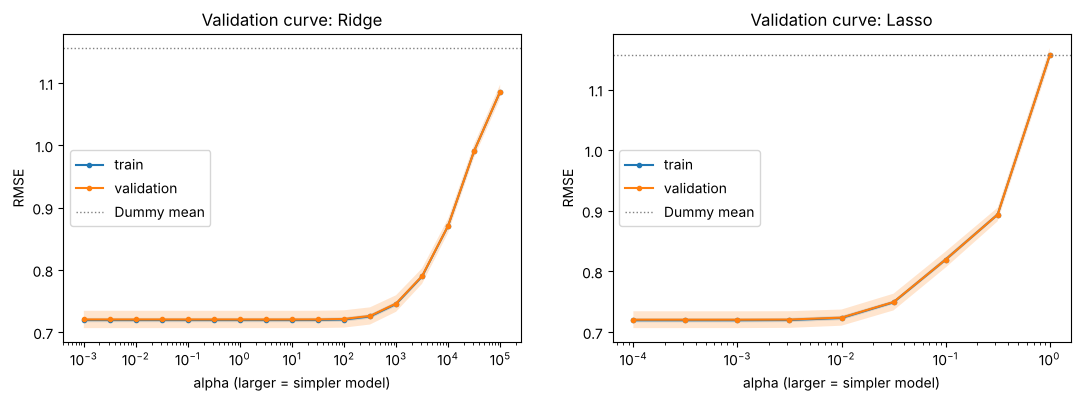

,train,val,val_std
alpha,,,
0.001,0.7196,0.7205,0.0139
0.010,0.7196,0.7205,0.0139
0.100,0.7196,0.7205,0.0139
1.000,0.7196,0.7205,0.0139
10.000,0.7196,0.7205,0.0139
100.000,0.7204,0.7213,0.0139
1000.000,0.7454,0.7461,0.0133
10000.000,0.8708,0.8710,0.0114
100000.000,1.0863,1.0864,0.0113


,train,val,val_std
alpha,,,
0.000100,0.7196,0.7205,0.0139
0.000316,0.7196,0.7205,0.0139
0.001000,0.7196,0.7205,0.0139
0.003162,0.7199,0.7207,0.0137
0.010000,0.7233,0.7239,0.0133
0.031623,0.7492,0.7496,0.0138
0.100000,0.8196,0.8196,0.0132
0.316228,0.8939,0.8939,0.0112
1.000000,1.1562,1.1562,0.0122


In [19]:
# 單一參數掃描：正則化強度 alpha（degree = 1，也就是原本的 8 個特徵）
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
vc_alpha = {}
for ax, (name, est, param, alphas) in zip(
    axes,
    [
        ("Ridge", make_pipeline(StandardScaler(), Ridge()), "ridge__alpha", np.logspace(-3, 5, 17)),
        ("Lasso", make_pipeline(StandardScaler(), Lasso(max_iter=10_000)), "lasso__alpha", np.logspace(-4, 0, 9)),
    ],
):
    tr, va = validation_curve(
        est, X_train, y_train, param_name=param, param_range=alphas, cv=cv,
        scoring="neg_root_mean_squared_error", n_jobs=-1,
    )
    tr, va = -tr, -va
    for label, s in [("train", tr), ("validation", va)]:
        ax.plot(alphas, s.mean(1), "o-", ms=3, label=label)
        ax.fill_between(alphas, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=0.2)
    ax.axhline(y_train.std(ddof=0), color="gray", ls=":", lw=1, label="Dummy mean")
    ax.set_xscale("log")
    ax.set_xlabel("alpha (larger = simpler model)")
    ax.set_ylabel("RMSE")
    ax.set_title(f"Validation curve: {name}")
    ax.legend()
    vc_alpha[name] = pd.DataFrame(
        {"train": tr.mean(1), "val": va.mean(1), "val_std": va.std(1)}, index=pd.Index(alphas, name="alpha")
    )
plt.show()
display(vc_alpha["Ridge"].iloc[::2].round(4))
display(vc_alpha["Lasso"].round(4))


### TODO 12（問答，補寫）

> **(1)** Ridge 的 validation curve 幾乎是一條水平線，跟第三章邏輯回歸的 C 曲線很不一樣。
>
> **(a)** 讀表：$\alpha$ = 0.001、100、$10^4$ 時 train 與 val RMSE 各是多少？train 與 val 的差距多大？
>
> **(b)** 一般判斷：train 很低、val 明顯較高 → 過擬合；train 和 val 一樣高、差距很小 → 欠擬合。這份資料的線性模型屬於哪一種？
>
> **(c)** 正則化的作用是「降低變異」。用參數個數（9 個）與樣本數（16,512 筆）解釋：為什麼這裡的變異本來就很小、正則化幫不上忙？

**(a)**

| $\alpha$ | train RMSE | val RMSE | val − train |
| --- | --- | --- | --- |
| 0.001 | 0.7196 | 0.7205 | 0.0009 |
| 100 | 0.7204 | 0.7213 | 0.0009 |
| $10^4$ | 0.8708 | 0.8710 | 0.0002 |

$\alpha \le 30$ 時兩條線完全不動；$\alpha \ge 300$ 之後一起往上（往 Dummy 的 1.156 靠近）。

**(b)** **欠擬合（高偏差）**：train 與 val 幾乎重疊（差 0.001，比 fold 間的標準差 0.014 還小），而且都停在 0.72 —— 模型連訓練資料都學不好，不是「背太多」。

**(c)** 變異來自「換一批訓練資料，學到的模型差多少」。

- 只有 9 個參數、卻有 16,512 筆資料：每個參數平均由 1,800 多筆資料決定，換一批資料係數幾乎不變（OLS 係數的變異 $\propto \sigma^2 / n$）。
- 正則化用「多一點偏差」換「少一點變異」；變異本來就接近 0 時，這筆交易只剩下付出的偏差 → $\alpha$ 小時沒差，$\alpha$ 大時只會變差。
- 對照第三章：Breast Cancer 只有 455 筆、30 個特徵、而且線性可分，不加正則化時 $\|w\|$ 會無限長大，C 才有明顯的最佳點。
- **結論**：要改善線性回歸，方向不是加正則化，而是**增加容量**（下一格的多項式特徵）。

> **(2)** Lasso：$\alpha$ 從哪裡開始明顯變差？第 4 節試的 0.01 和 0.1 各落在曲線的哪一段？

- $\alpha \le 0.003$：與 OLS 相同（0.7205–0.7207）；$\alpha = 0.01$：0.7239（只差 0.003，不到一個 std）；$\alpha = 0.1$：0.8196，已經明顯欠擬合（TODO 11 (1)：砍掉了經緯度）；$\alpha = 1$：1.1562 = Dummy（所有係數都被壓成 0，只剩 bias = 平均）。
- 0.01 在「平坦區的邊緣」、0.1 已經在「上升段」。
- 第 6 節的測試集上 Lasso 0.01 的 R² 0.582 略高於 OLS 0.576，但 CV 上反而略差 → 差距在雜訊範圍內，不能說 Lasso 比較好。


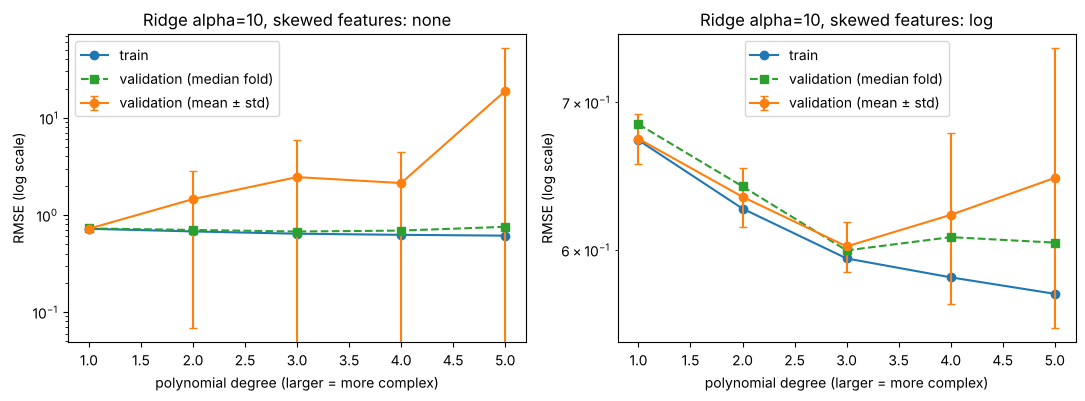

none                                       log                  \
         train      val  val_std val_median_fold   train     val val_std   
degree                                                                     
1       0.7196   0.7205   0.0139          0.7251  0.6727  0.6737  0.0174   
2       0.6756   1.4544   1.3861          0.7003  0.6263  0.6341  0.0194   
3       0.6401   2.4512   3.4156          0.6744  0.5946  0.6021  0.0158   
4       0.6233   2.1282   2.3087          0.6896  0.5830  0.6222  0.0553   
5       0.6114  18.9222  33.2917          0.7543  0.5731  0.6467  0.0937   

                        
       val_median_fold  
degree                  
1               0.6839  
2               0.6410  
3               0.5996  
4               0.6080  
5               0.6045

In [20]:
# 容量：多項式次數。固定 alpha = 10，比較「原始特徵」與「長尾特徵先取 log1p」
log_tf = ColumnTransformer(
    [("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), SKEWED)],
    remainder="passthrough",
    verbose_feature_names_out=False,
)


def poly_ridge(tf: ColumnTransformer | str = "passthrough", degree: int = 1, alpha: float = 1.0) -> Pipeline:
    """前處理 tf →（多項式展開）→ 標準化 → Ridge。tf 為 "passthrough" 表示不做前處理。"""
    return Pipeline(
        [
            ("tf", tf),
            ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=alpha)),
        ]
    )


degrees = [1, 2, 3, 4, 5]
vc_deg = {}
for name, tf in [("none", "passthrough"), ("log", log_tf)]:
    tr, va = validation_curve(
        poly_ridge(tf, alpha=10.0), X_train, y_train, param_name="poly__degree", param_range=degrees,
        cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1,
    )
    tr, va = -tr, -va
    vc_deg[name] = pd.DataFrame(
        {"train": tr.mean(1), "val": va.mean(1), "val_std": va.std(1), "val_median_fold": np.median(va, axis=1)},
        index=pd.Index(degrees, name="degree"),
    )

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, name in zip(axes, ["none", "log"]):
    t = vc_deg[name]
    ax.plot(degrees, t["train"], "o-", label="train")
    ax.errorbar(degrees, t["val"], yerr=t["val_std"], fmt="o-", capsize=3, label="validation (mean ± std)")
    ax.plot(degrees, t["val_median_fold"], "s--", label="validation (median fold)")
    ax.set_yscale("log")
    ax.set_xlabel("polynomial degree (larger = more complex)")
    ax.set_ylabel("RMSE (log scale)")
    ax.set_title(f"Ridge alpha=10, skewed features: {name}")
    ax.legend()
plt.show()
display(pd.concat(vc_deg, axis=1).round(4))


In [21]:
# 是誰把 RMSE 弄爆的？degree 2、不取 log：每一筆訓練資料的 CV 預測（每筆都由「沒看過它」的模型預測）
deg2 = poly_ridge("passthrough", degree=2, alpha=10.0)
pred_cv = cross_val_predict(deg2, X_train, y_train, cv=cv)
abs_err = np.abs(pred_cv - y_train.to_numpy())

worst = np.argsort(-abs_err)[:5]
display(X_train.iloc[worst][SKEWED + ["MedInc"]].assign(y=y_train.iloc[worst], cv_pred=pred_cv[worst].round(2)))
print(f"誤差最大的 5 筆佔總平方誤差的比例：{(abs_err[worst] ** 2).sum() / (abs_err ** 2).sum():.1%}")

fold_tbl = []
for f, (_, va_idx) in enumerate(cv.split(X_train)):
    e = abs_err[va_idx]
    fold_tbl.append({"fold": f, "RMSE": np.sqrt((e ** 2).mean()), "MAE": e.mean(), "max |error|": e.max()})
display(pd.DataFrame(fold_tbl).set_index("fold").round(3))
print("對照 degree 1：", cv_summary(poly_ridge("passthrough", 1, 10.0)))
print("      degree 2：", cv_summary(deg2))


,AveRooms,AveBedrms,Population,AveOccup,MedInc,y,cv_pred
19006,3.166667,0.833333,7460.0,1243.333333,10.2264,1.37500,240.20
3364,5.142857,1.142857,4198.0,599.714286,5.5179,0.67500,-43.59
13034,8.275862,1.517241,6675.0,230.172414,6.1359,2.25000,-4.88
8874,7.285714,1.214286,1154.0,41.214286,9.3370,5.00001,-1.36
1914,141.909091,25.636364,30.0,2.727273,1.8750,5.00001,10.44


誤差最大的 5 筆佔總平方誤差的比例：88.7%


,RMSE,MAE,max |error|
fold,,,
0,4.213,0.575,238.823
1,1.028,0.502,44.263
2,0.658,0.482,3.949
3,0.700,0.509,4.603
4,0.673,0.499,3.752


對照 degree 1： {'rmse': '0.7205 ± 0.0139', 'mae': '0.5290 ± 0.0094', 'r2': '0.6115 ± 0.0123'}
      degree 2： {'rmse': '1.4544 ± 1.3861', 'mae': '0.5134 ± 0.0320', 'r2': '-1.9393 ± 4.9649'}


### TODO 13（問答，補寫）

> **(1)** 不取 log 的多項式：
>
> **(a)** 讀表：degree 2、3 的 val RMSE「平均」、「標準差」、「中位數 fold」各是多少？train RMSE 呢？
>
> **(b)** 平均跟中位數差很多、標準差比平均還大，代表 5 個 fold 的分數長什麼樣子？（看 fold 表）
>
> **(c)** 定義：RMSE $= \sqrt{\frac{1}{n}\sum e_i^2}$、MAE $= \frac{1}{n}\sum |e_i|$。degree 2 的 MAE 比 degree 1 好（0.513 vs 0.529），RMSE 卻差了一倍（1.454 vs 0.721）。用「誤差取平方」解釋為什麼兩個指標結論相反。

**(a)**

| degree | train | val 平均 | val 標準差 | val 中位數 fold |
| --- | --- | --- | --- | --- |
| 1 | 0.720 | 0.721 | 0.014 | 0.725 |
| 2 | 0.676 | 1.454 | 1.386 | 0.700 |
| 3 | 0.640 | 2.451 | 3.416 | 0.674 |

train 隨 degree 穩定下降；val 的中位數也在下降（比 degree 1 好），平均卻暴增。

**(b)** 大部分 fold 正常、**少數 fold 爆掉**：degree 2 的 fold 0 RMSE 4.21、fold 1 1.03，其餘 3 個 fold 在 0.66–0.70；MAE 卻每個 fold 都在 0.48–0.58，看不出異狀。平均被一個 fold 拉高，中位數不受影響 —— 跟 TODO 2 (2)「平均 vs 中位數」是同一件事，只是這次發生在 fold 的分數上。

**(c)** RMSE 先把誤差平方再平均：一筆誤差 200 的樣本貢獻 $200^2 = 40{,}000$，抵得過 $40{,}000 / 0.5^2 = 16$ 萬筆誤差 0.5 的樣本。MAE 只把它算成 200，對 3,000 多筆的 fold 平均來說影響不大。

- 所以 degree 2 對「大多數樣本」其實預測得更準（MAE、中位數 fold 都變好），但對**極少數樣本**錯得離譜，RMSE 被這幾筆主導（誤差最大的 5 筆佔總平方誤差 88.7%）。
- **兩個指標都對，回答的是不同問題**：MAE 是「一般樣本差多少」，RMSE 會特別懲罰「災難性的錯誤」。房價預測若一筆預測成 2,000 萬美元會造成實際損失，RMSE 的警告就很重要。

> **(2)** 誤差最大的 5 筆：
>
> **(a)** 它們的特徵值有什麼共同點？對照 TODO 1 (2) 的長尾表格。
>
> **(b)** degree 2 的模型裡有 AveOccup²、AveRooms × AveOccup 這種項。訓練時如果沒看過這麼大的值，這些項的係數有被「約束」住嗎？為什麼爆掉的只有某些 fold？
>
> **(c)** 取 log1p 之後，為什麼同樣的多項式就不會爆？

**(a)** 都帶有長尾特徵的極端值：前三筆的 AveOccup 是 1,243、600、230（一般街區約 3），第五筆是 AveRooms 141.9、AveBedrms 25.6 —— 正是 TODO 1 (2) 表格的 max 欄。CV 預測分別是 240（真值 1.4）、−43.6（真值 0.7）、−4.9、10.4 這種完全不合理的值。

**(b)** 沒有。係數是從訓練資料學的；某個方向上如果所有訓練樣本的值都在正常範圍，模型只需要讓係數在「正常範圍內」表現好，在範圍外會發生什麼完全沒有被約束 —— 這就是**外插**（extrapolation）。

- 多項式讓外插更嚴重：$x$ 超出範圍 10 倍，$x^2$ 就超出 100 倍、$x^3$ 超出 1,000 倍。
- 極端值只有十幾筆（TODO 1 (2)：AveOccup > 3 × p99 的只有 14 筆）。KFold 隨機分配：某個極端樣本被分到驗證 fold、而訓練 fold 裡沒有跟它一樣極端的樣本時，它就爆掉。所以爆不爆取決於「誰被分到哪個 fold」→ fold 間的變異極大（標準差 > 平均）。
- （高變異 = 過擬合的另一種樣子：模型對「哪些資料剛好在訓練集裡」非常敏感。）

**(c)** log 把乘法尺度壓成加法尺度：AveOccup 1,243 → 7.1、正常值 3 → 1.4，極端值只比一般值大 5 倍而不是 400 倍；平方之後也只大 25 倍。外插的距離變短 → 錯也錯不遠。

- 實測 log 版本：degree 2 val 0.634 ± 0.019、degree 3 0.602 ± 0.016，標準差回到正常大小。

> **(3)** 取 log 的版本：degree 從 1 到 5，train 一直下降，val 在哪裡最低？哪一段欠擬合、哪一段開始過擬合？

| degree | train | val | val − train |
| --- | --- | --- | --- |
| 1 | 0.673 | 0.674 | 0.001 |
| 2 | 0.626 | 0.634 | 0.008 |
| 3 | 0.595 | 0.602 | 0.008 |
| 4 | 0.583 | 0.622 | 0.039 |
| 5 | 0.573 | 0.647 | 0.074 |

- val 在 **degree 3 最低**（0.602）。
- degree 1–2：train、val 一起下降、差距很小 → 仍在欠擬合，增加容量有幫助。
- degree 4–5：train 繼續下降，val 反轉上升、差距擴大到 0.04–0.07，標準差也變大（0.055、0.094）→ 開始過擬合。
- 注意 degree 1 只取 log 就從 0.721 降到 0.674：**前處理本身也是在改變模型能表達的函數**（log 讓模型能表達「人數翻倍，房價變化固定」這種關係）。


best_params_： {'poly__degree': 3, 'ridge__alpha': np.float64(10.0), 'tf': 'log'}   CV RMSE： 0.6021


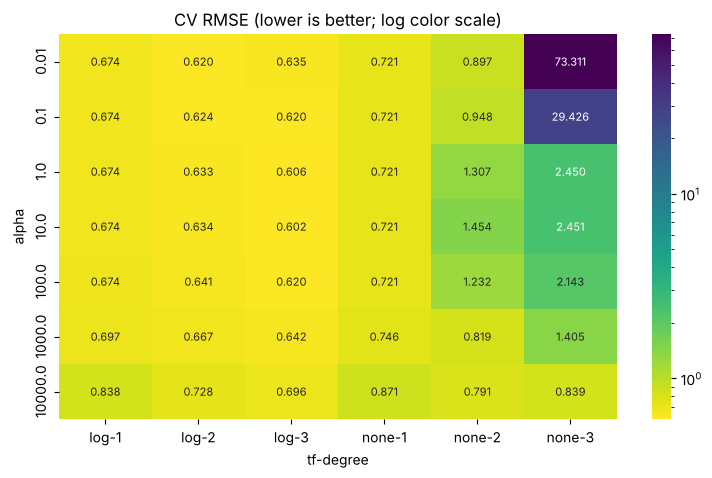

In [22]:
# 搜尋：前處理 × degree × alpha（2 × 3 × 7 = 42 組）
param_grid = {
    "tf": ["passthrough", log_tf],
    "poly__degree": [1, 2, 3],
    "ridge__alpha": np.logspace(-2, 4, 7),
}
gs = GridSearchCV(poly_ridge(), param_grid, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
gs.fit(X_train, y_train)

res = pd.DataFrame(
    {
        "tf": ["none" if isinstance(t, str) else "log" for t in gs.cv_results_["param_tf"]],
        "degree": gs.cv_results_["param_poly__degree"].astype(int),
        "alpha": gs.cv_results_["param_ridge__alpha"].astype(float),
        "mean": -gs.cv_results_["mean_test_score"],
        "std": gs.cv_results_["std_test_score"],
    }
)
print("best_params_：", {k: ("log" if k == "tf" and not isinstance(v, str) else v) for k, v in gs.best_params_.items()},
      "  CV RMSE：", round(-gs.best_score_, 4))

from matplotlib.colors import LogNorm

tbl = res.pivot_table(index="alpha", columns=["tf", "degree"], values="mean")
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(tbl, annot=True, fmt=".3f", cmap="viridis_r", norm=LogNorm(), ax=ax, annot_kws={"size": 8})
ax.set_title("CV RMSE (lower is better; log color scale)")
plt.show()


In [23]:
# one-standard-error rule：跟最佳差距不到一個標準差的候選中，挑「最簡單」的
best = res.loc[res["mean"].idxmin()]

# TODO 14（程式）
#   - ok：mean ≤ best.mean + best.std 的所有列（RMSE 越低越好，方向跟第四章 accuracy 相反、跟第三章 log loss 相同）
#   - choice：ok 裡最簡單的一列。這裡的「簡單」：degree 小優先；degree 相同時 alpha 大優先（壓得越多越簡單）；
#     再相同時 tf = "none" 優先（少一個前處理）
#   - 提示：sort_values(["degree", "alpha", "tf"], ascending=[True, False, False]).iloc[0]
#     （字串排序："none" > "log"，想想 tf 那一欄的 ascending 為什麼是 False）
ok = res[res["mean"] <= best["mean"] + best["std"]]
choice = ok.sort_values(["degree", "alpha", "tf"], ascending=[True, False, False]).iloc[0]

print("CV 最佳 ：", best.to_dict())
print("1-SE 候選：")
display(ok.round(4))
print("1-SE 選擇：", choice.to_dict())
print("✅ 1-SE 應選到 degree = 3、alpha = 10、tf = log")

model_1se = poly_ridge(
    log_tf if choice["tf"] == "log" else "passthrough", int(choice["degree"]), float(choice["alpha"])
).fit(X_train, y_train)
print("展開後的特徵數：", model_1se["poly"].n_output_features_)


CV 最佳 ： {'tf': 'log', 'degree': 3, 'alpha': 10.0, 'mean': 0.6021093567469292, 'std': 0.015792740652346957}
1-SE 候選：


,tf,degree,alpha,mean,std
33,log,3,1.0,0.6062,0.0302
35,log,3,10.0,0.6021,0.0158


1-SE 選擇： {'tf': 'log', 'degree': 3, 'alpha': 10.0, 'mean': 0.6021093567469292, 'std': 0.015792740652346957}
✅ 1-SE 應選到 degree = 3、alpha = 10、tf = log
展開後的特徵數： 164


### TODO 15（問答，補寫）

> **(1)** 看 heatmap：
>
> **(a)** none 的 degree 2、3 兩欄，alpha 從 0.01 增加到 $10^4$，RMSE 怎麼變？
>
> **(b)** 為什麼很大的 alpha 能「救」不取 log 的多項式？救得到 log 版本的水準嗎？
>
> **(c)** log 的三欄：最佳落在哪一格？

**(a)** degree 3：73.3 → 29.4 → 2.45 → … → 0.84（$\alpha = 10^4$）；degree 2：0.90–1.45 之間亂跳，到 $10^4$ 才 0.79。整體趨勢是 alpha 越大越不會爆，但需要非常大的 alpha。

**(b)** Ridge 把係數往 0 壓 → 高次項的係數變小 → 外插時 $w \cdot x^3$ 沒那麼大。但 alpha 是「所有係數一起壓」：要壓到極端值不爆，有用的係數也被壓扁了 → 最好也只到 0.79，比 log 版本的 degree 1（0.674）還差。

- **教訓**：正則化是「對係數」的處理，log 是「對特徵」的處理。問題出在特徵的尺度（長尾）時，從特徵下手比較對症；正則化只能用偏差換變異。

**(c)** log、degree 3、$\alpha = 10$：0.6021。同一欄 $\alpha = 1$ 是 0.6062、$\alpha = 0.01$ 是 0.6345 —— degree 3 有 164 個特徵，這時正則化終於有用了（對照 TODO 12：degree 1 時 alpha 完全沒作用）。

> **(2)** 1-SE rule 選到什麼？跟 CV 最佳一樣嗎？為什麼這次沒有換成更簡單的模型？

- 門檻 = 最佳 0.6021 + 一個標準差 0.0158 = 0.6179。只有兩組進得來：log、degree 3、$\alpha = 1$（0.6062）與 $\alpha = 10$（0.6021，就是最佳）。
- 依「degree 小 → alpha 大」排序，兩組 degree 都是 3，alpha 大的是 10 → **1-SE 選到的就是 CV 最佳**。
- 更簡單的 degree 2（最好 0.6204）已經超出門檻（差距 0.018 > 1 std）：從 degree 2 到 3 的進步是「統計上看得出來」的，不是雜訊。
- 對照第三、四章：1-SE 會不會換模型取決於資料；它不是一定要換，而是「差距在雜訊內才換」。


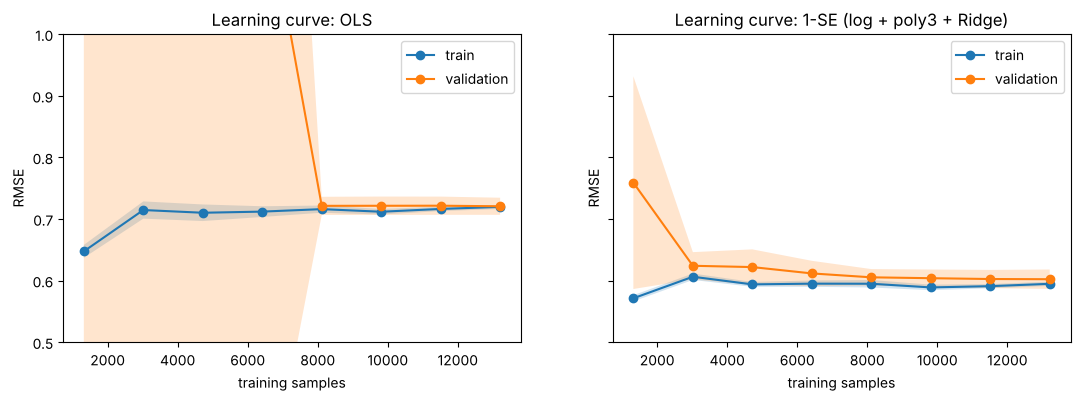

OLS                         1-SE (log + poly3 + Ridge)                  \
       n   train     val val_std                          n   train     val   
0   1320  0.6473  2.1438  1.7874                       1320  0.5712  0.7589   
1   3019  0.7144  1.7084  1.9764                       3019  0.6061  0.6239   
2   4717  0.7100  1.6704  1.8934                       4717  0.5937  0.6218   
3   6415  0.7119  1.2535  1.0512                       6415  0.5949  0.6115   
4   8114  0.7159  0.7212  0.0147                       8114  0.5948  0.6052   
5   9812  0.7116  0.7213  0.0150                       9812  0.5888  0.6038   
6  11510  0.7162  0.7214  0.0148                      11510  0.5908  0.6024   
7  13209  0.7196  0.7205  0.0139                      13209  0.5946  0.6021   

           
  val_std  
0  0.1726  
1  0.0221  
2  0.0288  
3  0.0205  
4  0.0134  
5  0.0141  
6  0.0148  
7  0.0158

In [24]:
# 學習曲線：再多一點資料會更好嗎？（OLS vs 1-SE 模型）
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
lc = {}
for ax, (name, m) in zip(
    axes, [("OLS", make_pipeline(StandardScaler(), LinearRegression())), ("1-SE (log + poly3 + Ridge)", model_1se)]
):
    sizes, tr, va = learning_curve(
        m, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error",
        train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1,
    )
    tr, va = -tr, -va
    for label, s in [("train", tr), ("validation", va)]:
        ax.plot(sizes, s.mean(1), "o-", label=label)
        ax.fill_between(sizes, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=0.2)
    ax.set_ylim(0.5, 1.0)
    ax.set_xlabel("training samples")
    ax.set_ylabel("RMSE")
    ax.set_title(f"Learning curve: {name}")
    ax.legend()
    lc[name] = pd.DataFrame({"n": sizes, "train": tr.mean(1), "val": va.mean(1), "val_std": va.std(1)})
plt.show()
display(pd.concat(lc, axis=1).round(4))


### TODO 16（問答，補寫）

> **(1)** 學習曲線：
>
> **(a)** OLS：n ≥ 8,000 之後 train 與 val 各多少？再加資料有用嗎？
>
> **(b)** n = 1,320 時 OLS 的 val RMSE 是 2.14 ± 1.79 —— 連一次的線性模型也爆掉了。用 TODO 13 (2) 解釋。
>
> **(c)** 1-SE 模型：train 與 val 的差距多大？瓶頸變成什麼？

**(a)** train 約 0.71–0.72、val 約 0.72，兩條線已經貼在一起而且是平的 → 再加資料不會進步。這是**高偏差**的典型學習曲線：模型能力已經用完了，要的是更多容量（或更好的特徵），不是更多資料。

**(b)** 樣本少時，訓練集更可能「沒抽到」某個極端值（例如 AveOccup 1,243），而它出現在驗證 fold 時，線性項 $w \cdot x$ 一樣會外插出很大的誤差。資料多到 8,000 筆以上，訓練集幾乎一定包含各種極端值，係數在那些方向也被約束住了 → 標準差從 1.8 降到 0.015。

- 推論：**極端值造成的問題，會在小樣本、高次項、或兩者同時出現時放大**。

**(c)** train 0.595、val 0.602，差 0.007；val 從 n ≈ 5,000 起就幾乎不再下降 → 又回到「偏差為主」，只是偏差小了很多（val 0.72 → 0.60）。

- 剩下的瓶頸：截斷的 y（TODO 1 (1)，模型修不了標籤的偏差）、地理位置仍只能用多項式曲面近似（待補強：到海岸／城市的距離）、以及線性模型 + 多項式這個函數族本身（第 8、10 章的樹模型可以學任意的交互作用）。


---
## 6. 測試集評估

模型都已經用 CV 決定好，測試集只評估一次。


,mae,rmse,r2,mape
Dummy mean,0.9061,1.1449,-0.0002,62.8861
LinReg normal-eq (scratch),0.5332,0.7456,0.5758,31.9522
LinReg GD (scratch),0.5332,0.7456,0.5758,31.9518
Ridge a=1 (scratch),0.5332,0.7456,0.5758,31.9512
LinearRegression (sklearn),0.5332,0.7456,0.5758,31.9522
Ridge a=1 (sklearn),0.5332,0.7456,0.5758,31.9512
Lasso a=0.01 (sklearn),0.5353,0.7404,0.5816,32.0066
Lasso a=0.1 (sklearn),0.6222,0.8244,0.4814,39.9724
ElasticNet a=0.01 (sklearn),0.5341,0.7416,0.5803,31.9413
"Ridge poly3 + log (1-SE, sklearn)",0.4331,0.6054,0.7203,26.0820


,model,rmse,time,mae,r2,mape,params,notes
0,"Ridge poly3 + log (1-SE, sklearn)",0.6054,2026-10-24 20:34,0.4331,0.7203,26.0820,"{""tf"": ""log"", ""degree"": 3, ""alpha"": 10.0}",NaN
1,Lasso a=0.01 (sklearn),0.7404,2026-10-24 20:34,0.5353,0.5816,32.0066,NaN,NaN
2,ElasticNet a=0.01 (sklearn),0.7416,2026-10-24 20:34,0.5341,0.5803,31.9413,NaN,NaN
3,LinReg normal-eq (scratch),0.7456,2026-10-24 20:34,0.5332,0.5758,31.9522,"{""scaled"": true}",NaN
4,Ridge a=1 (sklearn),0.7456,2026-10-24 20:34,0.5332,0.5758,31.9512,NaN,NaN
5,LinearRegression (sklearn),0.7456,2026-10-24 20:34,0.5332,0.5758,31.9522,NaN,NaN
6,Ridge a=1 (scratch),0.7456,2026-10-24 20:34,0.5332,0.5758,31.9512,"{""alpha"": 1.0}",NaN
7,LinReg GD (scratch),0.7456,2026-10-24 20:34,0.5332,0.5758,31.9518,"{""lr"": 0.1, ""epochs"": 776}",NaN
8,Lasso a=0.1 (sklearn),0.8244,2026-10-24 20:34,0.6222,0.4814,39.9724,NaN,NaN
9,Dummy mean,1.1449,2026-10-24 20:34,0.9061,-0.0002,62.8861,NaN,NaN


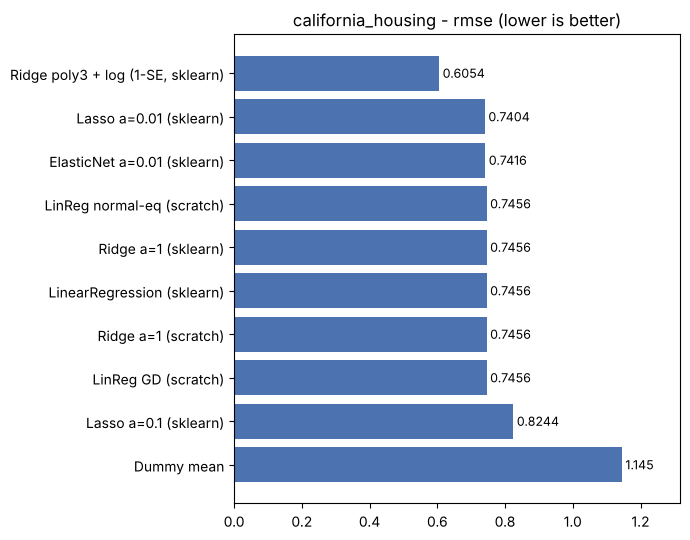

In [25]:
from ml_dl_llm.results import compare, log_result

BENCH = "california_housing"

# 名稱: (模型, 對應的測試資料, 要記下的參數)
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
eval_models = {
    "Dummy mean": (dummy, X_test, {}),
    "LinReg normal-eq (scratch)": (ne_s, X_test_s, {"scaled": True}),
    "LinReg GD (scratch)": (gd, X_test_s, {"lr": gd.lr, "epochs": len(gd.loss_history_)}),
    "Ridge a=1 (scratch)": (ridge_s, X_test_s, {"alpha": ridge_s.alpha}),
}
for name, m in sk_models.items():
    eval_models[name] = (m, X_test, {})  # sklearn pipeline 吃原始資料
eval_models["Ridge poly3 + log (1-SE, sklearn)"] = (
    model_1se,
    X_test,
    {"tf": choice["tf"], "degree": int(choice["degree"]), "alpha": float(choice["alpha"])},
)

test_scores = {}
for name, (m, X, params) in eval_models.items():
    metrics = regression_metrics(y_test, m.predict(X))
    test_scores[name] = metrics
    log_result(BENCH, name, metrics, **params)

display(pd.DataFrame(test_scores).T)
compare(BENCH, "rmse", higher_is_better=False)

---
## 7. 診斷

上排是 OLS（第 3、4 節），下排是調參後的 1-SE 模型（log + 3 次多項式 + Ridge）。


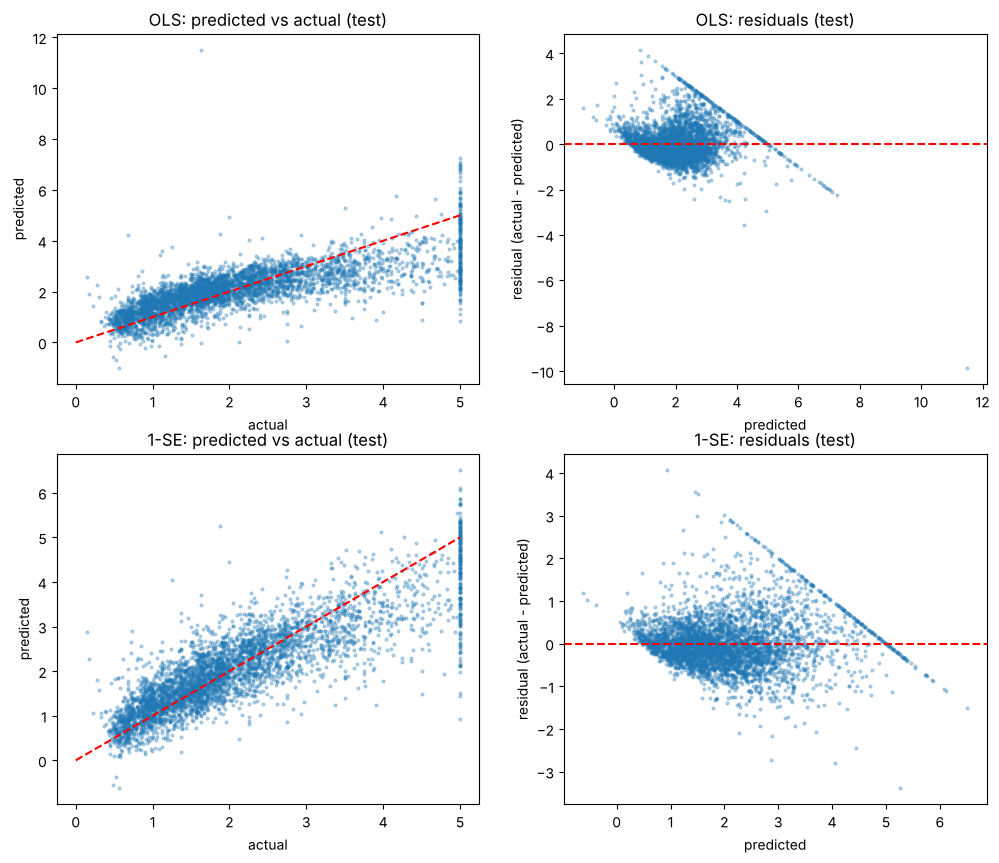

測試集截斷樣本（y ≥ 5）：184 筆


,負房價預測筆數,最大預測值,截斷樣本的平均殘差,非截斷樣本 RMSE,殘差標準差（依預測值五分位）
OLS,15,11.5,1.153,0.6578,"[0.581, 0.569, 0.713, 0.843, 0.926]"
1-SE,3,6.51,0.847,0.5483,"[0.382, 0.486, 0.587, 0.694, 0.782]"


In [26]:
# 診斷圖：預測 vs 實際、殘差（測試集）
diag_models = {"OLS": ne_s.predict(X_test_s), "1-SE": model_1se.predict(X_test)}
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for row, (name, y_pred) in zip(axes, diag_models.items()):
    resid = y_test - y_pred
    row[0].scatter(y_test, y_pred, s=4, alpha=0.3)
    row[0].plot([0, 5], [0, 5], "r--")
    row[0].set_xlabel("actual")
    row[0].set_ylabel("predicted")
    row[0].set_title(f"{name}: predicted vs actual (test)")
    row[1].scatter(y_pred, resid, s=4, alpha=0.3)
    row[1].axhline(0, color="r", ls="--")
    row[1].set_xlabel("predicted")
    row[1].set_ylabel("residual (actual - predicted)")
    row[1].set_title(f"{name}: residuals (test)")
plt.show()

censored = (y_test >= 5).to_numpy()
rows = {}
for name, y_pred in diag_models.items():
    resid = (y_test - y_pred).to_numpy()
    quintile = pd.qcut(y_pred, 5, labels=False)
    rows[name] = {
        "負房價預測筆數": int((y_pred < 0).sum()),
        "最大預測值": round(float(y_pred.max()), 2),
        "截斷樣本的平均殘差": round(float(resid[censored].mean()), 3),
        "非截斷樣本 RMSE": round(float(np.sqrt((resid[~censored] ** 2).mean())), 4),
        "殘差標準差（依預測值五分位）": pd.Series(resid).groupby(quintile).std().round(3).tolist(),
    }
print(f"測試集截斷樣本（y ≥ 5）：{censored.sum()} 筆")
display(pd.DataFrame(rows).T)


### TODO 17（問答）本章總結

> **(1)** 右邊 actual = 5 那一排發生什麼事？跟 EDA 的截斷有什麼關係？

- actual = 5 處形成一條垂直柱：這些樣本真實房價 ≥ 50 萬美元，但標籤被截斷（censored）記為 5.00001。
- 模型對它們的預測分散在約 2～6 之間、多數低於 5 → 系統性低估。
- 問題不在「外推」，而在訓練標籤本身有偏：被壓低的 y 會把回歸斜率往下拉，連帶影響其他高價區的預測。
- 處理方式：移除截斷樣本（簡單但會偏離真實分布）、或用 censored regression（如 Tobit）明確建模上限。

> **(2)** 殘差圖有沒有明顯的「結構」（斜線、扇形）？有結構代表模型漏掉了什麼？

兩種結構：

① **左上到右下、斜率 −1 的直線**：即 (1) 的截斷樣本。actual 固定為 5，殘差 $= 5 - \hat{y}$，故對 $\hat{y}$ 作圖必為斜率 −1 的直線；這是標籤截斷的假象，而非模型漏抓的特徵關係。

② **扇形**：$\hat{y}$ 越大殘差離散程度越大 → 異質變異（heteroscedasticity），違反 OLS「誤差變異為常數」的假設，使係數的標準誤與信賴區間失準（點估計仍不偏）。常見對策是對 y 取 log（或 Box-Cox）以穩定變異，而非加高次項；漏掉非線性項通常表現為殘差對 $\hat{y}$ 呈彎曲趨勢（如 U 形）。

另：測試集出現 15 筆負房價預測，線性模型輸出無正值約束；$\log(y)$ 轉換也能一併解決。

> **(3)** 這份資料線性模型的 R² 大概卡在多少？你覺得瓶頸是模型還是特徵？

合理正則化下的線性模型 test $R^2 \approx 0.58$（RMSE ≈ 0.74，約 7.4 萬美元）；Lasso $\alpha = 0.1$ 的 0.48 是過度正則化（欠擬合）造成，不代表線性模型上限。

瓶頸是「線性模型 × 原始特徵」的組合 —— 即 y 與特徵的關係非線性，而線性模型只能表達原始特徵的線性組合：

- 經緯度只能形成一個平面（如「越往北越便宜」），無法表達「靠海」或舊金山／洛杉磯等高價聚落；
- MedInc 與 y 有飽和、截斷等非線性；Rooms／Occup 等有極端值與長尾。

兩條改進路線：

1. 保留線性模型、改善特徵：$\log(y)$、log／分箱處理長尾特徵、多項式與交互作用項、經緯度分群或到海岸／城市的距離；
2. 改用能自動學習非線性與交互作用的模型：樹模型（Random Forest、GBDT）在此資料 $R^2$ 可達 0.8 以上。

**補充（第 5 節驗證）**：路線 1 確實有效 —— 長尾特徵取 log1p ＋ 3 次多項式 ＋ Ridge（$\alpha = 10$），test $R^2$ 從 0.576 升到 0.720、RMSE 0.746 → 0.605，仍然是「線性模型」（對 164 個展開後的特徵是線性的）。瓶頸的確主要在「原始特徵的形式」，而不是線性回歸這個方法本身。

> **(4)（補寫）** 比較上下兩排與下方的統計表：調參後的模型改善了哪些問題？哪些問題完全沒有改善？為什麼？

| | OLS | 1-SE | 說明 |
| --- | --- | --- | --- |
| 負房價預測 | 15 筆 | 3 筆 | 曲面比平面更能貼合低價區；但輸出仍沒有正值約束 |
| 最大預測值 | 11.5 | 6.5 | 少了極端外插（log 讓極端街區不再被線性項放大） |
| 截斷樣本平均殘差 | +1.15 | +0.85 | 仍然系統性低估：標籤本身被壓在 5，換模型修不了 |
| 非截斷樣本 RMSE | 0.658 | 0.548 | 一般樣本的改善最明顯 |
| 殘差標準差（低 → 高預測值） | 0.58 → 0.93 | 0.38 → 0.78 | 整體變小，但「預測越高、誤差越大」的扇形還在 |

- **改善的**：模型能力相關的問題 —— 非線性（MedInc 的彎曲、地理位置）、極端值的外插。
- **沒改善的**：資料本身的問題 —— ① **截斷**：斜率 −1 的那條線還在，只是往左移（預測值變大了一點，但真值仍被記成 5）；② **異質變異**：高價區的房價本來就比低價區更分散（同樣 ±10% 的波動，50 萬的房子是 ±5 萬、10 萬的房子只有 ±1 萬），這是 y 的尺度性質，要靠對 y 取 log（`TransformedTargetRegressor`）處理，而不是加特徵。
- → 第 5 節調的是 $x$ 那一側；剩下的問題都在 $y$ 那一側（待補強）。

---
## 8. 本章小結

### 方法與結果

California Housing（train 16,512 / test 4,128；CV = 5-fold KFold）。

| 方法 | 求解方式 | 關鍵性質 | CV RMSE | test RMSE | test R² |
| --- | --- | --- | --- | --- | --- |
| Dummy mean | 預測訓練集平均 | RMSE = y 的標準差；R² ≈ 0（CV 時略小於 0） | 1.156 ± 0.012 | 1.145 | −0.000 |
| OLS（正規方程，手寫） | 解 (XᵀX)θ = Xᵀy | 一步得解；κ(XᵀX) = κ(X)²，病態時數值不穩 | 0.721 ± 0.014 | 0.746 | 0.576 |
| OLS（梯度下降，手寫） | θ ← θ − lr·∇MSE | 需 lr < 2/λ_max；收斂步數 ∝ κ → 必須標準化 | — | 0.746 | 0.576 |
| Ridge α=1 | 解 (XᵀX + αI′)θ = Xᵀy | 墊高 λ_min、穩定共線係數；不產生 0 係數 | 0.721 ± 0.014 | 0.746 | 0.576 |
| Lasso α=0.01 | 座標下降＋soft-thresholding | 無閉式解；產生稀疏解、兼具特徵選擇 | 0.724 ± 0.013 | 0.740 | 0.582 |
| Lasso α=0.1 | 同上 | 過度正則化：砍掉經緯度 → 欠擬合 | 0.820 ± 0.013 | 0.824 | 0.481 |
| ElasticNet α=0.01 | 座標下降 | L1 + L2，稀疏且傾向成組保留相關特徵 | — | 0.742 | 0.580 |
| **log1p + 3 次多項式 + Ridge α=10（1-SE）** | 長尾特徵取 log → 164 個多項式特徵 → Ridge | 容量來自特徵擴充；log 防止外插爆炸 | **0.602 ± 0.016** | **0.605** | **0.720** |

手寫版本與 sklearn 係數差異約 1e-15，驗證實作正確。

### 核心觀念

1. **最小平方法**：最小化 ‖Xw − y‖²，令梯度為 0 得正規方程；bias 以補一欄 1 併入 θ。最小化 MSE 的預測是條件**平均**（Dummy mean 是 MSE 最小的常數；median 則是 MAE 最小的常數）。
2. **條件數 κ = λ_max / λ_min**
   - 直接解方程組時：誤差放大倍數（κ ≈ 10ᵏ 約損失 k 位有效數字）。
   - 梯度下降時：lr 上限由 λ_max 決定、最慢方向進度由 λ_min 決定 → 收斂步數 ∝ κ。
   - 本資料：raw κ ≈ 5.6e10 → 標準化後 ≈ 43。
3. **標準化**：不改變 OLS 的預測值（係數依 w_scaled = w_raw·σ 換算），但大幅改善條件數；對 Ridge／Lasso 則是必要條件，否則懲罰對不同單位的特徵不公平。標準化**不改變分布形狀**，處理不了長尾。
4. **共線性**：使多元回歸係數不穩定、可與單變量相關係數反號（AveRooms／AveBedrms）。Ridge 傾向讓共線特徵平均分攤權重；Lasso 傾向只保留其中一個。
5. **L1 vs L2**：L1 在 0 不可微 → 無閉式解、但能把係數壓成恰為 0；L2 可微 → 閉式解、只縮小不歸零。
6. **sklearn 的 α 定義不一致**：Ridge 為 ‖y − Xw‖² + α‖w‖²，Lasso 為 (1/2n)‖y − Xw‖² + α‖w‖₁，兩者 α 不可直接比較；用交叉驗證選。
7. **R² 與 RMSE**：R² = 1 − SSE/SST =「比永遠猜平均好多少」，可以是負的；RMSE 對大誤差敏感（平方），MAE 不敏感。兩者結論不同時，代表誤差被少數樣本主導。
8. **欠擬合時正則化沒用**：n = 16,512、只有 9 個參數 → 變異本來就接近 0，validation curve 是水平線；要改善得**增加容量**（多項式特徵），容量大了（164 個特徵）正則化才開始有用（α = 10 最佳）。
9. **外插與長尾特徵**：線性與多項式模型對 x 沒有上限，極端值（AveOccup 1,243 是 p99 的 230 倍）在 x²、x³ 下被放大成災難性預測（240 vs 真值 1.4）；只在某些 fold 爆 → CV 標準差 > 平均。log1p 保留順序、壓縮尺度，是比加大 α 更對症的處理（前處理也是超參數）。
10. **學習曲線**：train ≈ val 且都平 → 高偏差，加資料沒用；小樣本時極端值沒被涵蓋，連線性模型都會外插失敗。
11. **診斷要分清 x 側與 y 側的問題**：非線性、長尾特徵可以靠特徵工程修；標籤截斷（斜率 −1 的殘差線、系統性低估）與異質變異（扇形）在 y 側，換特徵修不了。

### 待補強（之後回來可以學）

**統計推論面（本章偏重預測，未涉及）**
- [ ] OLS 的統計假設（線性、獨立、同質變異、常態誤差）與 Gauss-Markov 定理（BLUE）
- [ ] 係數的標準誤、t 檢定、信賴區間；用 `statsmodels.OLS` 看 summary 表
- [ ] 異質變異的檢定（Breusch-Pagan）與穩健標準誤（HC0–HC3）
- [ ] 多重共線性的量化：VIF（variance inflation factor）
- [ ] 最小平方法 = 高斯誤差下的最大概似估計（MLE）；Ridge／Lasso = 高斯／Laplace 先驗下的 MAP

**數值與最佳化**
- [ ] 用 QR 分解或 SVD（`np.linalg.lstsq`）解最小平方，避免條件數平方；偽逆（pseudo-inverse）
- [ ] 隨機梯度下降（SGD）與 mini-batch：大資料下的做法，以及學習率排程
- [ ] 動量（Momentum）、Adam 如何緩解病態條件數（銜接第二章神經網路）
- [ ] 手寫座標下降 Lasso（soft-thresholding）；LARS 與 Lasso 路徑

**模型與特徵**
- [x] 用交叉驗證選 α 並畫驗證曲線（第 5 節）
- [x] 偏差—變異權衡：用 α 與多項式次數觀察欠擬合／過擬合（第 5 節）
- [x] 長尾特徵取 log、多項式特徵（第 5 節：test R² 0.576 → 0.720）
- [ ] 對 y 取 log（`TransformedTargetRegressor`）處理異質變異與負房價；注意 log 空間的預測要轉回原空間時的偏差（smearing）
- [ ] 經緯度的特徵工程：分群（K-Means，第 11 章）、到海岸／大城市的距離、RBF 特徵
- [ ] 截斷資料的處理：移除 y = 5 樣本的影響、Tobit 回歸
- [ ] 穩健回歸：Huber、RANSAC（對極端值較不敏感）；quantile regression（預測條件中位數或分位數）
- [ ] 廣義線性模型（GLM）：Poisson、Gamma 回歸，處理正值或計數型目標
- [ ] 極端值造成的 fold 間變異：用 `RepeatedKFold` 評估 CV 分數本身有多穩定
